# EDA — Stroke Prediction

> **The same work as the report, in a notebook.** Nothing here is new: every cell below is the
> code of `code/`, as it is there, in the order `main.py` runs it, one cell per definition. Running the whole
> notebook writes the same figures to `figures/` and the same tables and numbers to `results/` as
> `python code/main.py` does. The report itself is [`index.md`](index.md), next to this notebook.

Stages 1 to 3 of the report — the target and the split, each feature, then the features against each other and
against the target — come from `eda.py`; the outliers, the pipeline checks and the dimensionality reduction come
from `reduction.py`.

In [1]:
from pathlib import Path
from IPython.display import Image, Markdown, display

# The notebook runs from anywhere inside the repository and uses the same paths as the scripts.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mkdocs.yml").is_file())
CODE_DIR = REPO / "docs" / "projects" / "eda" / "code"


def show_figures(*numbers):
    """Show the figures the scripts just wrote to figures/."""
    for n in numbers:
        display(Image(filename=str(FIGURES_DIR / f"fig{n}.png")))


def show_tables(step):
    """Show the tables of one step, as the report prints them."""
    display(Markdown((RESULTS_DIR / f"{step}_tables.md").read_text()))

## [`code/preprocessing.py`](code/preprocessing.py) — the data, the split and the preprocessing pipeline

In [2]:
"""Data loading, the train/test split and the preprocessing pipeline of the Stroke EDA.

Importable: nothing is fitted at import time. Typical use from the modeling deliverable:

    from preprocessing import load_raw, split, build_preprocessor
    X_train, X_test, y_train, y_test = split(load_raw())
    preprocess = build_preprocessor()
    X_train_t = preprocess.fit_transform(X_train)   # fit on train only
    X_test_t = preprocess.transform(X_test)         # test is only transformed

Every choice in build_preprocessor() is motivated in section 4A of the report.
"""

from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

SEED = 42
DATA_PATH = REPO / "data" / "stroke-prediction" / "healthcare-dataset-stroke-data.csv"

TARGET = "stroke"
ID_COLUMN = "id"
SKEWED_FEATURES = ["avg_glucose_level", "bmi"]      # right-skewed (skewness > 1): log1p, then standardize
SYMMETRIC_FEATURES = ["age"]                         # near-symmetric: standardize only
NUMERICAL_FEATURES = SYMMETRIC_FEATURES + SKEWED_FEATURES
CATEGORICAL_FEATURES = ["gender", "hypertension", "heart_disease", "ever_married",
                        "work_type", "Residence_type", "smoking_status"]
FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

### `load_raw`

In [3]:
def load_raw(path=DATA_PATH):
    """Read the CSV exactly as published. The text 'N/A' in bmi is parsed as NaN by pandas."""
    return pd.read_csv(path)

### `split`

In [4]:
def split(df, test_size=0.2):
    """Stratified 80/20 split with a fixed seed; returns X_train, X_test, y_train, y_test.

    The file is sorted by the target (every positive comes first), so the split must shuffle;
    stratification keeps the minority rate the same in both parts.
    """
    X = df[FEATURES]
    y = df[TARGET]
    return train_test_split(X, y, test_size=test_size, stratify=y, shuffle=True, random_state=SEED)

### `build_preprocessor`

In [5]:
def build_preprocessor():
    """Return an unfitted ColumnTransformer whose output is a dense, finite matrix.

    - age: median imputation (a safeguard: the column has no missing value) + standardization;
    - avg_glucose_level, bmi: median imputation + log1p + standardization;
    - bmi missing indicator: 0/1, kept unscaled;
    - categorical: constant imputation + full one-hot (no dropped level, so no category is
      placed closer to the others than they are to each other); a category never seen in
      training is encoded as an all-zero block, so it is never confused with a known one.
    """
    symmetric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    skewed = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", symmetric, SYMMETRIC_FEATURES),
        ("log", skewed, SKEWED_FEATURES),
        ("missing", MissingIndicator(features="all"), ["bmi"]),
        ("cat", categorical, CATEGORICAL_FEATURES),
    ], remainder="drop")

## [`code/common.py`](code/common.py) — paths, colors, figure saving and result collection

In [6]:
"""Paths, colors, figure saving and result collection shared by eda.py and reduction.py."""

import json
from pathlib import Path

import matplotlib

matplotlib.use("Agg")  # render straight to files, so the scripts also run without a display
import matplotlib.pyplot as plt
import numpy as np

HERE = CODE_DIR
REPORT = HERE.parent / "index.md"
FIGURES_DIR = HERE.parent / "figures"
RESULTS_DIR = HERE.parent / "results"

CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}   # colorblind-safe pair (blue / orange)
CLASS_LABELS = {0: "No stroke (0)", 1: "Stroke (1)"}
GROUP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
NEUTRAL = "#898781"
UNITS = {"age": "Age (years)", "avg_glucose_level": "Average glucose level (mg/dL, inferred)", "bmi": "BMI (kg/m²)"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "legend.fontsize": 8, "legend.framealpha": 0.9,
})

### `save_figure`

In [7]:
def save_figure(fig, number, title):
    """Give the figure its numbered title and write it to figures/fig{number}.png."""
    FIGURES_DIR.mkdir(exist_ok=True)
    fig.suptitle(f"Figure {number} — {title}", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.3 / fig.get_figheight()))   # keep the panels clear of the title
    fig.savefig(FIGURES_DIR / f"fig{number}.png", bbox_inches="tight")
    plt.close(fig)

### `md_table`

In [8]:
def md_table(df, floatfmt=None):
    """Render a DataFrame as a Markdown table; floatfmt maps a column to its format spec (default .2f).

    Integers get a thousands separator and negative numbers a true minus sign, as in the prose.
    """
    floatfmt = floatfmt or {}
    header = "| " + " | ".join(str(c) for c in df.columns) + " |"
    rule = "|" + "|".join("---" for _ in df.columns) + "|"
    rows = []
    for values in df.astype(object).itertuples(index=False):   # object dtype keeps each cell's own type
        cells = []
        for c, v in zip(df.columns, values):
            if isinstance(v, (float, np.floating)):
                text = format(v, floatfmt.get(c, ".2f"))
            elif isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_)):
                text = f"{v:,}"
            else:
                text = str(v)
            if isinstance(v, (int, float, np.number)) and text.startswith("-"):
                text = "−" + text[1:]
            cells.append(text)
        rows.append("| " + " | ".join(cells) + " |")
    return "\n".join([header, rule, *rows])

### `format_p`

In [9]:
def format_p(p):
    """A p-value with two significant figures: scientific notation below 0.001, trailing zeros kept above."""
    return f"{p:.1e}" if p < 0.001 else f"{p:#.2g}"

### `wilson_interval`

In [10]:
def wilson_interval(successes, n, z=1.96):
    """95% Wilson score interval for a proportion (stable for small n and rates near 0)."""
    if n == 0:
        return 0.0, 0.0
    p = successes / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, center - half), min(1.0, center + half)

### `Results`

In [11]:
class Results:
    """Collects the numbered tables and the numbers one stage of the report quotes, then writes them to results/.

    Each table goes to results/table{NN}.csv and, rendered in Markdown, to results/{name}_tables.md; the numbers
    go to results/{name}_metrics.json. The table numbers are the ones the report uses, so Table 9 of the report
    is results/table09.csv.
    """

    def __init__(self, name):
        self.name = name
        self.metrics = {}
        self.tables = []
        RESULTS_DIR.mkdir(exist_ok=True)

    def table(self, number, title, df, floatfmt=None):
        """Register Table `number` and write its CSV."""
        self.tables.append(f"### Table {number} — {title}\n\n{md_table(df, floatfmt)}\n")
        df.to_csv(RESULTS_DIR / f"table{number:02d}.csv", index=False)

    def write(self):
        """Write the metrics JSON and the Markdown file with every table of this stage."""
        (RESULTS_DIR / f"{self.name}_metrics.json").write_text(
            json.dumps(self.metrics, indent=2, default=float) + "\n")
        (RESULTS_DIR / f"{self.name}_tables.md").write_text("\n".join(self.tables))

## [`code/eda.py`](code/eda.py) — stages 1 to 3: Tables 2–12 and Figures 1–8

In [12]:
"""Stages 1-3 of the EDA: inspection, univariate and bivariate analysis (Tables 2-12, Figures 1-8).

The full file is read only for the stage-1 inventory (missing values, duplicates, consistency
checks, the leakage audit and the target distribution). The split happens right after it, and
every later statistic and figure uses the training rows only.
"""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, pearsonr, spearmanr


NUM = NUMERICAL_FEATURES
CAT = CATEGORICAL_FEATURES
RARE_SHARE = 0.01          # a category below 1% of the training rows is flagged as rare
REDUNDANT_RHO = 0.80       # |rho| at or above this would flag a redundant numerical pair
VOCABULARY = {
    "gender": {"Female", "Male", "Other"}, "hypertension": {0, 1}, "heart_disease": {0, 1},
    "ever_married": {"Yes", "No"}, "work_type": {"Private", "Self-employed", "Govt_job", "children", "Never_worked"},
    "Residence_type": {"Urban", "Rural"}, "smoking_status": {"formerly smoked", "never smoked", "smokes", "Unknown"},
    "stroke": {0, 1},
}

### `stage1`

In [13]:
def stage1(raw, res):
    """1B quality, 1C target and 1D split; returns the training frame (features + target)."""
    m = res.metrics
    m["raw_shape"] = list(raw.shape)

    # 1B — missing values per column, full file (the inventory precedes the split)
    missing = pd.DataFrame({"column": raw.columns, "missing (count)": raw.isna().sum().values,
                            "missing (%)": raw.isna().mean().values * 100})
    res.table(2, "Missing values per column (full file)", missing, {"missing (%)": ".2f"})
    m["bmi_missing"] = int(raw["bmi"].isna().sum())
    m["bmi_missing_pct"] = float(raw["bmi"].isna().mean() * 100)

    # 1B — duplicates, impossible and inconsistent values
    checks = {
        "Fully duplicated rows": raw.duplicated().sum(),
        "Duplicated rows ignoring id": raw.drop(columns=ID_COLUMN).duplicated().sum(),
        "Repeated id": raw[ID_COLUMN].duplicated().sum(),
        "Constant columns": sum(raw[c].nunique(dropna=False) == 1 for c in raw.columns),
        "Values outside the documented vocabulary": sum((~raw[c].isin(v)).sum() for c, v in VOCABULARY.items()),
        "age <= 0 or age > 120": ((raw.age <= 0) | (raw.age > 120)).sum(),
        "Fractional age": (raw.age % 1 != 0).sum(),
        "avg_glucose_level <= 0": (raw.avg_glucose_level <= 0).sum(),
        "bmi < 12 (observed)": (raw.bmi < 12).sum(),
        "bmi > 60 (observed)": (raw.bmi > 60).sum(),
        "work_type = children with age >= 18": ((raw.work_type == "children") & (raw.age >= 18)).sum(),
        "ever_married = Yes with age < 18": ((raw.ever_married == "Yes") & (raw.age < 18)).sum(),
        "smoking_status = smokes with age < 12": ((raw.smoking_status == "smokes") & (raw.age < 12)).sum(),
        "smoking_status = Unknown": (raw.smoking_status == "Unknown").sum(),
        "smoking_status = Unknown with age < 18": ((raw.smoking_status == "Unknown") & (raw.age < 18)).sum(),
    }
    checks = {k: int(v) for k, v in checks.items()}
    m["checks"] = checks
    res.table(3, "Duplicates, impossible and inconsistent values (full file)",
              pd.DataFrame({"check": list(checks), "rows": list(checks.values())}))
    m["bmi_extremes"] = sorted(raw.bmi.dropna().nlargest(4).tolist(), reverse=True)
    m["age_min"], m["age_max"] = float(raw.age.min()), float(raw.age.max())
    m["gender_other_rows"] = int((raw.gender == "Other").sum())
    m["id_distinct"] = int(raw[ID_COLUMN].nunique())
    m["fractional_age_max"] = float(raw.age[raw.age % 1 != 0].max())
    m["children_age_max"] = float(raw.age[raw.work_type == "children"].max())
    m["never_worked_age_range"] = [float(raw.age[raw.work_type == "Never_worked"].min()),
                                   float(raw.age[raw.work_type == "Never_worked"].max())]
    m["smokers_under_12_ages"] = raw.age[(raw.smoking_status == "smokes") & (raw.age < 12)].tolist()
    m["bmi_below_12"] = raw.loc[raw.bmi < 12, ["age", "bmi"]].values.tolist()

    # 1B — leakage audit: the identifier, the row order and the bmi missingness pattern
    rho_id, p_id = spearmanr(raw[ID_COLUMN], raw[TARGET])
    positives_at = np.flatnonzero(raw[TARGET].to_numpy() == 1)
    m["id_target_spearman"], m["id_target_p"] = float(rho_id), float(p_id)
    m["positives_first_row"], m["positives_last_row"] = int(positives_at.min()), int(positives_at.max())
    m["last20_positives"] = int(raw[TARGET].iloc[int(len(raw) * 0.8):].sum())
    by_missing = raw.groupby(raw.bmi.isna())[TARGET].agg(["count", "sum", "mean"])
    m["stroke_rate_bmi_missing_full"] = float(by_missing.loc[True, "mean"] * 100)
    m["stroke_rate_bmi_observed_full"] = float(by_missing.loc[False, "mean"] * 100)
    m["strokes_bmi_missing_full"] = int(by_missing.loc[True, "sum"])
    # the course's smoking-gun check: correlation of each numerical feature and 0/1 flag with the target
    target_corr = {}
    for c in NUM + ["hypertension", "heart_disease"]:
        pair = raw[[c, TARGET]].dropna()
        target_corr[c] = float(pearsonr(pair[c], pair[TARGET]).statistic)
    m["target_corr"] = target_corr
    m["max_abs_target_corr"] = max(target_corr.items(), key=lambda kv: abs(kv[1]))
    # full-file medians, kept only to show in 4C that the pipeline's medians are the training ones
    m["bmi_median_full"], m["glucose_median_full"] = float(raw.bmi.median()), float(raw.avg_glucose_level.median())

    # 1C — target distribution
    counts = raw[TARGET].value_counts().sort_index()
    m["n_pos"], m["n_neg"] = int(counts[1]), int(counts[0])
    m["pos_pct"] = float(counts[1] / len(raw) * 100)
    m["imbalance_ratio"] = float(counts[0] / counts[1])

    # 1D — stratified split before any preprocessing decision
    X_train, X_test, y_train, y_test = split(raw)
    assert set(X_train.index).isdisjoint(X_test.index) and len(X_train) + len(X_test) == len(raw)
    m["train_rows"], m["test_rows"] = len(X_train), len(X_test)
    split_ids = pd.concat([
        pd.DataFrame({"row": X_train.index, "id": raw.loc[X_train.index, ID_COLUMN], "partition": "train"}),
        pd.DataFrame({"row": X_test.index, "id": raw.loc[X_test.index, ID_COLUMN], "partition": "test"}),
    ])
    split_ids.to_csv(RESULTS_DIR / "split.csv", index=False)
    target_rows = []
    for part, y in [("Full file", raw[TARGET]), ("Train", y_train), ("Test", y_test)]:
        target_rows.append({"partition": part, "rows": len(y), "stroke = 0": int((y == 0).sum()),
                            "stroke = 1": int((y == 1).sum()), "stroke = 1 (%)": float(y.mean() * 100)})
    target_table = pd.DataFrame(target_rows)
    res.table(4, "Target distribution in the full file and after the stratified split", target_table,
              {"stroke = 1 (%)": ".2f"})
    m["train_pos"], m["test_pos"] = int(y_train.sum()), int(y_test.sum())
    m["train_pos_pct"], m["test_pos_pct"] = float(y_train.mean() * 100), float(y_test.mean() * 100)
    m["train_bmi_missing"] = int(X_train.bmi.isna().sum())
    m["train_bmi_missing_pct"] = float(X_train.bmi.isna().mean() * 100)

    # Figure 1 — class counts and where the positives sit in the file
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    ax = axes[0]
    bars = ax.bar([CLASS_LABELS[0], CLASS_LABELS[1]], counts.values, color=[CLASS_COLORS[0], CLASS_COLORS[1]],
                  width=0.6)
    for bar, n in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, n + 60, f"{n:,} ({n / len(raw):.2%})", ha="center")
    ax.set(title=f"Class frequencies (full file, {len(raw):,} rows)", xlabel="Target class", ylabel="Rows",
           ylim=(0, counts.max() * 1.15))
    ax.legend(handles=[Patch(color=CLASS_COLORS[k], label=CLASS_LABELS[k]) for k in (0, 1)], loc="upper right")
    ax = axes[1]
    row = np.arange(len(raw))
    ax.plot(row, raw[TARGET].cumsum(), color=CLASS_COLORS[1], lw=2, label="Cumulative positives (stroke = 1)")
    ax.axvline(int(len(raw) * 0.8), color=NEUTRAL, ls="--", lw=1.2, label="Last 20% of the file (unshuffled 'test')")
    ax.set(title="Positives by position in the CSV: the file is sorted by target",
           xlabel="Row position in the CSV", ylabel="Cumulative positives (stroke = 1)")
    ax.legend(loc="center right")
    save_figure(fig, 1, f"Target: {m['pos_pct']:.2f}% positives, all stored at the top of the file")

    train = X_train.assign(**{TARGET: y_train})
    return train

### `stage2`

In [14]:
def stage2(train, res):
    """2A numerical and 2B categorical distributions (training rows only)."""
    m = res.metrics
    rows = []
    for c in NUM:
        x = train[c].dropna()
        rows.append({"feature": c, "count": len(x), "missing": int(train[c].isna().sum()),
                     "mean": x.mean(), "median": x.median(), "std": x.std(), "min": x.min(),
                     "Q1": x.quantile(.25), "Q3": x.quantile(.75), "max": x.max(),
                     "skewness": x.skew(), "excess kurtosis": x.kurt()})
    stats = pd.DataFrame(rows)
    res.table(5, "Descriptive statistics of the numerical features (train, observed values)", stats,
              {k: ".2f" for k in ["mean", "median", "std", "min", "Q1", "Q3", "max", "skewness", "excess kurtosis"]})
    m["numerical_stats"] = stats.set_index("feature").to_dict(orient="index")

    # Glucose: locate the two modes and the valley between them on a 10 mg/dL histogram. The main mode is the
    # tallest bin; the second mode is the bin to its right that rises most above the lowest bin in between
    glucose = train.avg_glucose_level
    hist, edges = np.histogram(glucose, bins=np.arange(50, glucose.max() + 10, 10))
    centers = (edges[:-1] + edges[1:]) / 2
    main = int(np.argmax(hist))
    rise = [hist[j] - hist[main:j + 1].min() for j in range(main + 1, len(hist))]
    second = main + 1 + int(np.argmax(rise))
    valley = main + int(np.argmin(hist[main:second + 1]))
    m["glucose_mode_low"], m["glucose_mode_high"] = float(centers[main]), float(centers[second])
    m["glucose_valley"] = float(centers[valley])
    high = glucose > m["glucose_valley"]   # the second mode: everything to the right of the valley
    m["glucose_high_rows"], m["glucose_high_pct"] = int(high.sum()), float(high.mean() * 100)
    # 2-year age bins [a, a + 2): the edges run one bin past the oldest age, so numpy's closed last bin
    # never merges three integer ages
    age_edges = np.arange(0, np.floor(train.age.max()) + 3, 2)
    age_counts = pd.Series(np.histogram(train.age, bins=age_edges)[0], index=age_edges[:-1].astype(int))
    m["age_tallest_bins"] = {f"{a}-{a + 2}": int(n) for a, n in age_counts.nlargest(2).items()}

    # Figure 2 — histograms with mean/median and boxplots (shape, modes, outliers)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), gridspec_kw={"height_ratios": [3, 1.5]})
    for j, c in enumerate(NUM):
        x = train[c].dropna()
        ax = axes[0, j]
        bins = {"age": age_edges, "avg_glucose_level": edges}.get(c, 40)   # glucose: the bins that found the modes
        ax.hist(x, bins=bins, color=CLASS_COLORS[0], alpha=0.85, edgecolor="white", linewidth=0.4,
                label=f"Training rows (n = {len(x):,})")
        ax.axvline(x.mean(), color="#0b0b0b", lw=1.5, label=f"Mean = {x.mean():.1f}")
        ax.axvline(x.median(), color=CLASS_COLORS[1], lw=1.5, ls="--", label=f"Median = {x.median():.1f}")
        ax.set(title=f"{c} — skewness {x.skew():.2f}".replace("-", "−"), xlabel=UNITS[c], ylabel="Rows")
        ax.legend(loc="upper left" if c == "age" else "upper right")
        ax = axes[1, j]
        ax.boxplot(x, orientation="horizontal", widths=0.45, patch_artist=True,
                   boxprops={"facecolor": "#b7d3f6"}, medianprops={"color": CLASS_COLORS[1]},
                   flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.4})
        q1, q3 = x.quantile(.25), x.quantile(.75)
        n_out = int(((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum())
        ax.set(xlabel=UNITS[c], yticks=[], ylabel="Train", ylim=(0.5, 1.7),
               title=f"Boxplot: {n_out} points beyond 1.5×IQR")
        ax.legend(handles=[Patch(facecolor="#b7d3f6", edgecolor="#0b0b0b",
                                 label="Box: Q1–Q3 · orange line: median · whiskers: 1.5×IQR"),
                           Line2D([], [], marker="o", color="#0b0b0b", ls="none", ms=3, alpha=0.4,
                                  label=f"{n_out} points beyond the fences")],
                  loc="upper right", fontsize=7)
    axes[0, 1].axvline(m["glucose_valley"], color=NEUTRAL, lw=1, ls=":",
                       label=f"Valley = {m['glucose_valley']:.0f} (second mode to the right)")
    axes[0, 1].legend(loc="upper right")
    save_figure(fig, 2, "Numerical features (train): near-symmetric age, bimodal glucose, right-skewed BMI")

    # 2B — frequencies, cardinality and rare categories
    rows = []
    for c in CAT:
        vc = train[c].value_counts()
        for k, n in vc.items():
            rows.append({"feature": c, "category": str(k), "count": int(n), "share (%)": n / len(train) * 100,
                         "cardinality": len(vc), "rare (< 1%)": "yes" if n / len(train) < RARE_SHARE else ""})
    freq = pd.DataFrame(rows)
    res.table(6, "Frequencies and cardinality of the categorical features (train)", freq, {"share (%)": ".2f"})
    rare = freq.loc[freq["rare (< 1%)"] == "yes", ["feature", "category", "count", "share (%)"]]
    m["rare_categories"] = rare.to_dict(orient="records")
    m["smoking_unknown_train"] = int((train.smoking_status == "Unknown").sum())
    m["smoking_unknown_train_pct"] = float((train.smoking_status == "Unknown").mean() * 100)
    m["children_rows_train"] = int((train.work_type == "children").sum())
    m["children_unknown_smoking_train"] = int(((train.work_type == "children")
                                               & (train.smoking_status == "Unknown")).sum())

    # Figure 3 — one bar panel per categorical feature + cardinality panel
    fig, axes = plt.subplots(4, 2, figsize=(12, 15))
    for ax, c in zip(axes.flat, CAT):
        vc = train[c].value_counts().sort_values()
        shares = vc / len(train) * 100
        colors = [CLASS_COLORS[1] if s < RARE_SHARE * 100 else CLASS_COLORS[0] for s in shares]
        ax.barh([str(k) for k in vc.index], vc.values, color=colors, height=0.6)
        for i, (n, s) in enumerate(zip(vc.values, shares)):
            rare_bar = s < RARE_SHARE * 100   # a rare bar is too thin to see, so its label carries the color
            ax.text(n + vc.max() * 0.02, i, f"{n:,} ({s:.1f}%)" if s >= 1 else f"{n:,} ({s:.2f}%)", va="center",
                    fontsize=8, color=CLASS_COLORS[1] if rare_bar else "#0b0b0b",
                    fontweight="bold" if rare_bar else "normal")
        ax.set(title=f"{c} — {len(vc)} categories", xlabel="Training rows", ylabel="Category",
               xlim=(0, vc.max() * 1.35))
    ax = axes.flat[-1]
    card = pd.Series({c: train[c].nunique() for c in CAT}).sort_values()
    ax.barh(card.index, card.values, color=NEUTRAL, height=0.6, label="Distinct categories")
    ax.set(title=f"Cardinality (id: {m['id_distinct']:,} distinct, dropped)", xlabel="Distinct categories in train",
           ylabel="Feature", xticks=range(0, 7))
    ax.legend(loc="lower right")
    fig.legend(handles=[Patch(color=CLASS_COLORS[0], label="Category with ≥ 1% of the training rows"),
                        Patch(color=CLASS_COLORS[1], label="Rare category: < 1% of the training rows")],
               loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.015), fontsize=10)
    save_figure(fig, 3, f"Categorical features (train): low cardinality, {len(m['rare_categories'])} rare categories")

### `stage3`

In [15]:
def stage3(train, res):
    """3A numerical x numerical, 3B categorical x target, 3C numerical x categorical (train only)."""
    m = res.metrics
    y = train[TARGET]

    # 3A — Pearson and Spearman on pairwise-complete observed values
    rows = []
    for i, a in enumerate(NUM):
        for b in NUM[i + 1:]:
            pair = train[[a, b]].dropna()
            rows.append({"pair": f"{a} × {b}", "n": len(pair), "Pearson r": pair[a].corr(pair[b]),
                         "Spearman ρ": spearmanr(pair[a], pair[b]).statistic})
    corr = pd.DataFrame(rows)
    top = corr.loc[corr["Spearman ρ"].abs().idxmax()]
    m["top_pair"], m["top_pair_rho"], m["top_pair_r"], m["top_pair_n"] = (
        top["pair"], float(top["Spearman ρ"]), float(top["Pearson r"]), int(top["n"]))
    m["redundant_pairs"] = int((corr["Spearman ρ"].abs() >= REDUNDANT_RHO).sum())
    adults = train[train.age >= 18][["age", "bmi"]].dropna()
    m["age_bmi_rho_adults"] = float(spearmanr(adults.age, adults.bmi).statistic)
    m["age_bmi_n_adults"] = len(adults)
    within = pd.DataFrame([{"pair": "age × bmi, adults only (age ≥ 18)", "n": len(adults),
                            "Pearson r": adults.age.corr(adults.bmi), "Spearman ρ": m["age_bmi_rho_adults"]}])
    res.table(7, "Pairwise correlations of the numerical features (train, observed values)",
              pd.concat([corr, within], ignore_index=True), {"Pearson r": ".3f", "Spearman ρ": ".3f"})

    # Figure 4 — the two coefficients side by side (method justification)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, method in zip(axes, ["pearson", "spearman"]):
        mat = train[NUM].corr(method=method)
        im = ax.imshow(mat, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(len(NUM)), NUM, rotation=20)
        ax.set_yticks(range(len(NUM)), NUM)
        ax.grid(False)
        for r in range(len(NUM)):
            for c in range(len(NUM)):
                ax.text(c, r, f"{mat.iloc[r, c]:.3f}", ha="center", va="center",
                        color="white" if abs(mat.iloc[r, c]) > 0.6 else "#0b0b0b")
        ax.set(title=f"{method.capitalize()} (pairwise-complete)", xlabel="Feature", ylabel="Feature")
        fig.colorbar(im, ax=ax, fraction=0.046, label=f"{method.capitalize()} coefficient")
        i, j = (NUM.index(f) for f in top["pair"].split(" × "))
        for r, c in ((i, j), (j, i)):
            ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="#0b0b0b", lw=2))
    fig.legend(handles=[Patch(facecolor="none", edgecolor="#0b0b0b", lw=2,
                              label=f"Strongest pair: {top['pair']} — no pair reaches the redundancy flag "
                                    f"|ρ| ≥ {REDUNDANT_RHO:.2f}")],
               loc="lower center", bbox_to_anchor=(0.5, -0.04), fontsize=9)
    save_figure(fig, 4, "Numerical correlations (train): no redundant pair, strongest is age × BMI")

    # Figure 5 — scatter plots of the three pairs, positives drawn on top
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    for ax, (_, r) in zip(axes, corr.iterrows()):
        a, b = r["pair"].split(" × ")
        for k in (0, 1):
            sel = train[y == k]
            ax.scatter(sel[a], sel[b], s=6 if k == 0 else 14, alpha=0.3 if k == 0 else 0.85,
                       color=CLASS_COLORS[k], label=CLASS_LABELS[k], edgecolors="none")
        ax.set(title=f"ρ = {r['Spearman ρ']:.3f} · r = {r['Pearson r']:.3f} · n = {r['n']:,}",
               xlabel=UNITS[a], ylabel=UNITS[b])
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, markerscale=2,
               bbox_to_anchor=(0.5, -0.06), fontsize=10)
    save_figure(fig, 5, "Numerical pairs (train): broad clouds, stroke cases concentrated at older ages")

    # 3B — stroke rate per category with 95% Wilson intervals; chi-square and Cramér's V per feature
    base = y.mean() * 100
    m["train_base_rate"] = float(base)
    rows, assoc = [], []
    for c in CAT:
        g = train.groupby(c)[TARGET].agg(["count", "sum"])
        for k, r in g.iterrows():
            lo, hi = wilson_interval(r["sum"], r["count"])
            rows.append({"feature": c, "category": str(k), "n": int(r["count"]), "strokes": int(r["sum"]),
                         "stroke rate (%)": r["sum"] / r["count"] * 100, "ci_lo": lo * 100, "ci_hi": hi * 100})
        table = pd.crosstab(train[c], y)
        # Pearson's chi-square without Yates' continuity correction (the correction only applies to 2x2 tables)
        chi2, p, dof, expected = chi2_contingency(table, correction=False)
        # expected counts below 5 invalidate the approximation: drop those categories and re-test
        small = table.index[(expected < 5).any(axis=1)]
        if len(small):
            kept = table.drop(index=small)
            p_k = chi2_contingency(kept, correction=False)[1]
            p_kept = f"{format_p(p_k)} (without {', '.join(map(str, small))})"
        else:
            p_kept = "—"
        assoc.append({"feature": c, "χ²": chi2, "dof": dof, "p-value": format_p(p),
                      "Cramér's V": np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))),
                      "min expected count": expected.min(), "p-value without the sparse categories": p_kept})
    rates = pd.DataFrame(rows)
    intervals = [f"{lo:.1f}–{hi:.1f}" for lo, hi in zip(rates.ci_lo, rates.ci_hi)]
    rates_table = rates.assign(**{"95% CI (%)": intervals}).drop(columns=["ci_lo", "ci_hi"])
    res.table(8, "Stroke rate per category (train) with 95% Wilson intervals", rates_table, {"stroke rate (%)": ".2f"})
    assoc = pd.DataFrame(assoc).sort_values("Cramér's V", ascending=False)
    res.table(9, "Association of each categorical feature with the target (train, χ² test of independence)", assoc,
              {"χ²": ".1f", "Cramér's V": ".3f", "min expected count": ".2f"})
    m["category_rates"] = rates_table.to_dict(orient="records")
    m["cramers_v"] = assoc.set_index("feature")["Cramér's V"].to_dict()

    # Figure 6 — category stroke rates with intervals, plus the Cramér's V ranking
    fig, axes = plt.subplots(4, 2, figsize=(12, 16))
    for ax, c in zip(axes.flat, CAT):
        sub = rates[rates.feature == c].reset_index(drop=True)
        rate, lo, hi = (sub[k].to_numpy() for k in ("stroke rate (%)", "ci_lo", "ci_hi"))
        ypos = np.arange(len(sub))
        ax.barh(ypos, rate, color=CLASS_COLORS[1], height=0.55, label="Stroke rate in category")
        ax.errorbar(rate, ypos, xerr=[rate - lo, hi - rate], fmt="none", ecolor="#0b0b0b",
                    capsize=3, lw=1, label="95% Wilson interval")
        ax.axvline(base, color=CLASS_COLORS[0], ls="--", lw=1.3, label=f"Train base rate {base:.2f}%")
        ax.set_yticks(ypos, [f"{k} (n={n:,})" for k, n in zip(sub.category, sub.n)])
        ax.set(title=c, xlabel="Stroke rate (%)", ylabel="Category (rows)", xlim=(0, 25))
        for i, upper in enumerate(hi):
            if upper > 25:  # tiny groups: the interval runs off the shared axis, so state its upper end
                ax.text(24.5, i + 0.3, f"interval to {upper:.0f}%", ha="right", fontsize=7)
        ax.legend(loc="lower right", fontsize=7)
    ax = axes.flat[-1]
    ax.barh(assoc.feature[::-1], assoc["Cramér's V"][::-1], color=NEUTRAL, height=0.55, label="Cramér's V")
    ax.set(title="Strength of association with stroke", xlabel="Cramér's V (0 = none)", ylabel="Feature")
    ax.legend(loc="lower right")
    binary = ["hypertension", "heart_disease", "ever_married"]
    ratios = {c: float(rates.loc[rates.feature == c, "stroke rate (%)"].max()
                       / rates.loc[rates.feature == c, "stroke rate (%)"].min()) for c in binary}
    m["binary_rate_ratios"] = ratios
    save_figure(fig, 6, "Unadjusted stroke rate by category (train): hypertension, heart disease and marriage "
                        f"multiply it by {min(ratios.values()):.1f}–{max(ratios.values()):.1f}")

    # 3C — grouped location (median) and spread (IQR) summaries
    def grouped(by, features):
        """Observed count, median, quartiles and IQR of each feature within each level of `by`."""
        out = []
        for f in features:
            for k, g in train.groupby(by):
                x = g[f].dropna()
                out.append({"feature": f, "group": f"{by} = {k}", "n": len(x), "median": x.median(),
                            "Q1": x.quantile(.25), "Q3": x.quantile(.75), "IQR": x.quantile(.75) - x.quantile(.25)})
        return pd.DataFrame(out)

    by_target = grouped(TARGET, NUM)
    # effect size next to the p-value: the single-feature AUC = U / (n1 · n0) measures class overlap
    pos = {f: train.loc[y == 1, f].dropna() for f in NUM}
    neg = {f: train.loc[y == 0, f].dropna() for f in NUM}
    tests = {f: mannwhitneyu(pos[f], neg[f]) for f in NUM}
    by_target["Mann–Whitney p"] = by_target.feature.map({f: format_p(t.pvalue) for f, t in tests.items()})
    by_target["AUC (feature alone)"] = by_target.feature.map(
        {f: t.statistic / (len(pos[f]) * len(neg[f])) for f, t in tests.items()})
    res.table(10, "Numerical features by target class (train): location and spread", by_target,
              {"median": ".2f", "Q1": ".2f", "Q3": ".2f", "IQR": ".2f", "AUC (feature alone)": ".3f"})
    m["by_target"] = by_target.to_dict(orient="records")
    m["positives_age_ge_60_pct"] = float((train.loc[y == 1, "age"] >= 60).mean() * 100)
    valley = m["glucose_valley"]
    high = train.avg_glucose_level > valley
    m["glucose_high_stroke_rate"] = float(train.loc[high, TARGET].mean() * 100)
    m["glucose_low_stroke_rate"] = float(train.loc[~high, TARGET].mean() * 100)
    m["glucose_high_age_median"] = float(train.loc[high, "age"].median())
    m["glucose_low_age_median"] = float(train.loc[~high, "age"].median())
    m["glucose_high_by_hypertension"] = {str(k): float((g.avg_glucose_level > valley).mean() * 100)
                                         for k, g in train.groupby("hypertension")}

    # Figure 7 — numerical features by class
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    for ax, f in zip(axes, NUM):
        data = [train.loc[y == k, f].dropna() for k in (0, 1)]
        bp = ax.boxplot(data, widths=0.55, patch_artist=True, medianprops={"color": "#0b0b0b"},
                        flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.35})
        for patch, k in zip(bp["boxes"], (0, 1)):
            patch.set_facecolor(CLASS_COLORS[k])
            patch.set_alpha(0.75)
        ax.set_xticks([1, 2], [f"{CLASS_LABELS[k]}\nn = {len(d):,}" for k, d in zip((0, 1), data)])
        iqr = [d.quantile(.75) - d.quantile(.25) for d in data]
        ax.set(title=f"{f}: median {data[0].median():.1f} → {data[1].median():.1f}, "
                     f"IQR {iqr[0]:.1f} → {iqr[1]:.1f}", xlabel="Target class", ylabel=UNITS[f])
    fig.legend(handles=[Patch(color=CLASS_COLORS[k], alpha=0.75, label=CLASS_LABELS[k]) for k in (0, 1)],
               loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06), fontsize=10)
    save_figure(fig, 7, "Numerical features by class (train): positives are older and spread over both glucose modes")

    # Figure 8 — confounding structure: age by work type and by smoking status, glucose by hypertension
    groups = [("work_type", "age"), ("smoking_status", "age"), ("hypertension", "avg_glucose_level")]
    other = pd.concat([grouped(by, [f]) for by, f in groups], ignore_index=True)
    res.table(11, "Numerical features grouped by categorical features (train): location and spread", other,
              {"median": ".2f", "Q1": ".2f", "Q3": ".2f", "IQR": ".2f"})
    m["grouped_other"] = other.to_dict(orient="records")
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
    for ax, (by, f) in zip(axes, groups):
        order = train.groupby(by)[f].median().sort_values().index.tolist()
        data = [train.loc[train[by] == k, f].dropna() for k in order]
        bp = ax.boxplot(data, widths=0.55, patch_artist=True, medianprops={"color": "#0b0b0b"},
                        flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.35})
        for patch, color in zip(bp["boxes"], GROUP_COLORS):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_xticks(range(1, len(order) + 1), [f"{k}\nn={len(d):,}" for k, d in zip(order, data)], fontsize=8)
        ax.set(title=f"{f} by {by}", xlabel=by, ylabel=UNITS[f], ylim=(None, train[f].max() * 1.3))
        ax.legend(handles=[Patch(color=c, alpha=0.7, label=f"{by} = {k}") for k, c in zip(order, GROUP_COLORS)],
                  loc="upper left", fontsize=7, ncol=2)
    save_figure(fig, 8, "Grouped boxplots (train): work type and smoking status are age proxies; "
                        "hypertension widens glucose")

    # Age-stratified check of the 3B associations: disjoint adult bands, 18-59 and 60+. gender and
    # Residence_type are left out because they show no association to begin with (Table 9)
    bands = {"18–59": (train.age >= 18) & (train.age < 60), "≥ 60": train.age >= 60}
    old = bands["≥ 60"]
    rows, band_tests = [], {}
    for c in ["hypertension", "heart_disease", "ever_married", "work_type", "smoking_status"]:
        sub = train[old]
        table = pd.crosstab(sub[c], sub[TARGET])
        # Fisher's exact test for the 2x2 tables, Pearson's chi-square (no correction) for the larger ones
        if table.shape == (2, 2):
            band_tests[c] = ("Fisher", float(fisher_exact(table).pvalue))
        else:
            band_tests[c] = ("χ²", float(chi2_contingency(table, correction=False)[1]))
        for k in sorted(train[c].unique(), key=str):
            sel = train[c] == k
            if not (sel & old).any():
                continue  # a category with no member aged 60 or more has no rate in that band
            row = {"feature": c, "category": str(k), "rate, all ages (%)": y[sel].mean() * 100}
            for band, mask in bands.items():
                row[f"n, {band}"] = int((sel & mask).sum())
                row[f"rate, {band} (%)"] = y[sel & mask].mean() * 100
            row["test p, ≥ 60"] = f"{format_p(band_tests[c][1])} ({band_tests[c][0]})"
            rows.append(row)
    strat = pd.DataFrame(rows)
    res.table(12, "Stroke rate per category within disjoint adult age bands (train)", strat,
              {"rate, all ages (%)": ".2f", "rate, 18–59 (%)": ".2f", "rate, ≥ 60 (%)": ".2f"})
    m["age_stratified"] = strat.to_dict(orient="records")
    m["band_tests_60"] = band_tests
    for status in ("No", "Yes"):
        group = train[old & (train.ever_married == status)]
        m[f"married_{status}_60"] = {"strokes": int(group[TARGET].sum()), "n": len(group),
                                     "wilson": [x * 100 for x in wilson_interval(group[TARGET].sum(), len(group))],
                                     "age_median": float(group.age.median())}
    young = bands["18–59"]
    m["band_tests_18_59"] = {c: float(fisher_exact(pd.crosstab(train.loc[young, c], y[young])).pvalue)
                             for c in ["hypertension", "heart_disease", "ever_married"]}
    m["rate_age_ge_60"], m["rate_age_lt_60"] = float(y[old].mean() * 100), float(y[~old].mean() * 100)
    m["positives_age_ge_60"] = int(y[old].sum())
    m["age_median_by_married"] = train.groupby("ever_married").age.median().to_dict()

### `eda_main`

In [16]:
def eda_main():
    """Run stages 1-3 and write Tables 2-12, Figures 1-8 and results/eda_metrics.json."""
    res = Results("eda")
    raw = load_raw()
    assert raw.shape == (5110, 12) and raw[ID_COLUMN].is_unique
    res.metrics["seed"] = SEED
    res.metrics["features"] = FEATURES
    train = stage1(raw, res)
    stage2(train, res)
    stage3(train, res)
    res.write()
    print(f"Stages 1-3 done: {len(res.tables)} tables, Figures 1-8 written.")

# Run — stages 1 to 3

`eda.main()`, one stage per cell, with the figures of each stage shown as they are written.

In [17]:
res = Results("eda")
raw = load_raw()
assert raw.shape == (5110, 12) and raw[ID_COLUMN].is_unique
res.metrics["seed"] = SEED
res.metrics["features"] = FEATURES
raw.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### Stage 1 — the target, the split and data quality (Table 2–4, Figure 1)

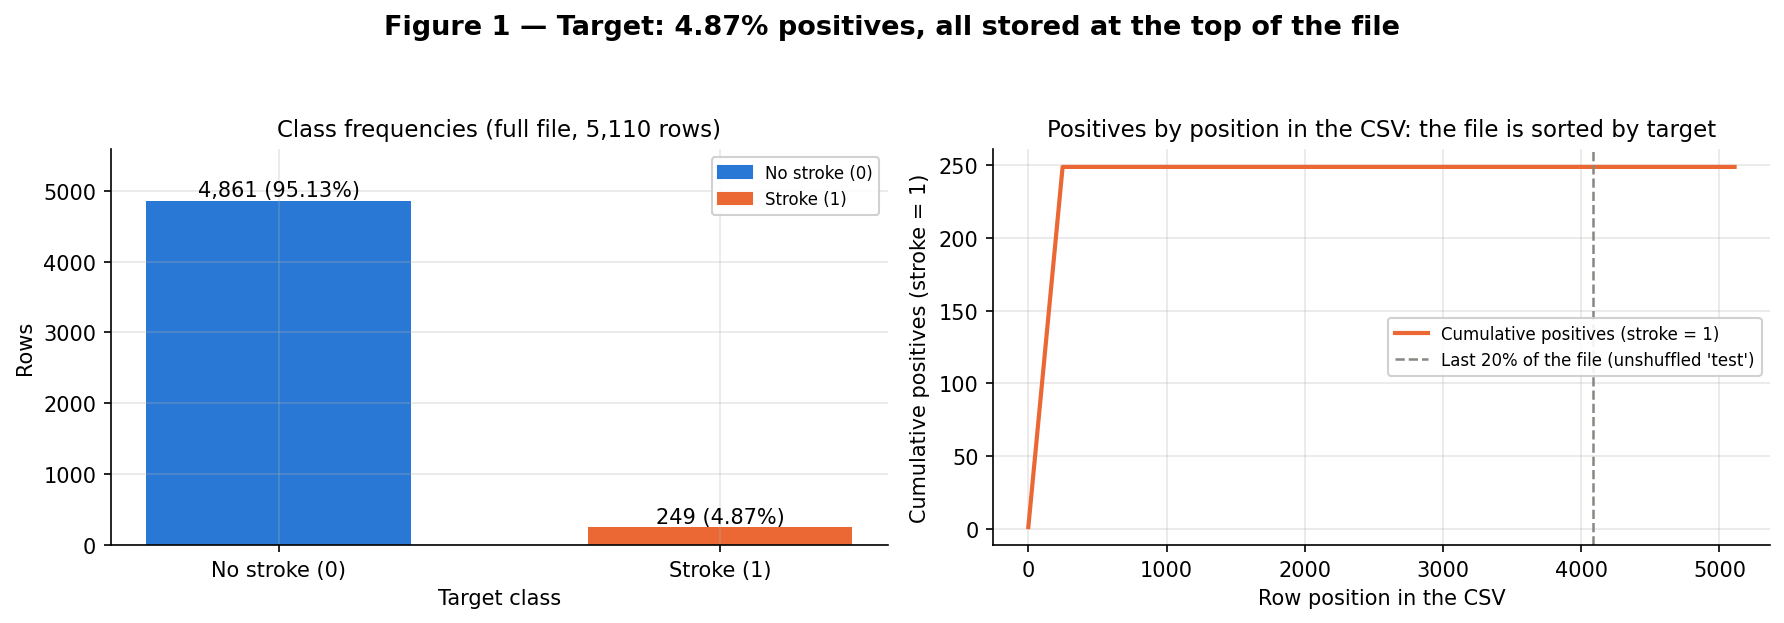

In [18]:
train = stage1(raw, res)
show_figures(1)

### Stage 2 — the features one by one (Figures 2–3)

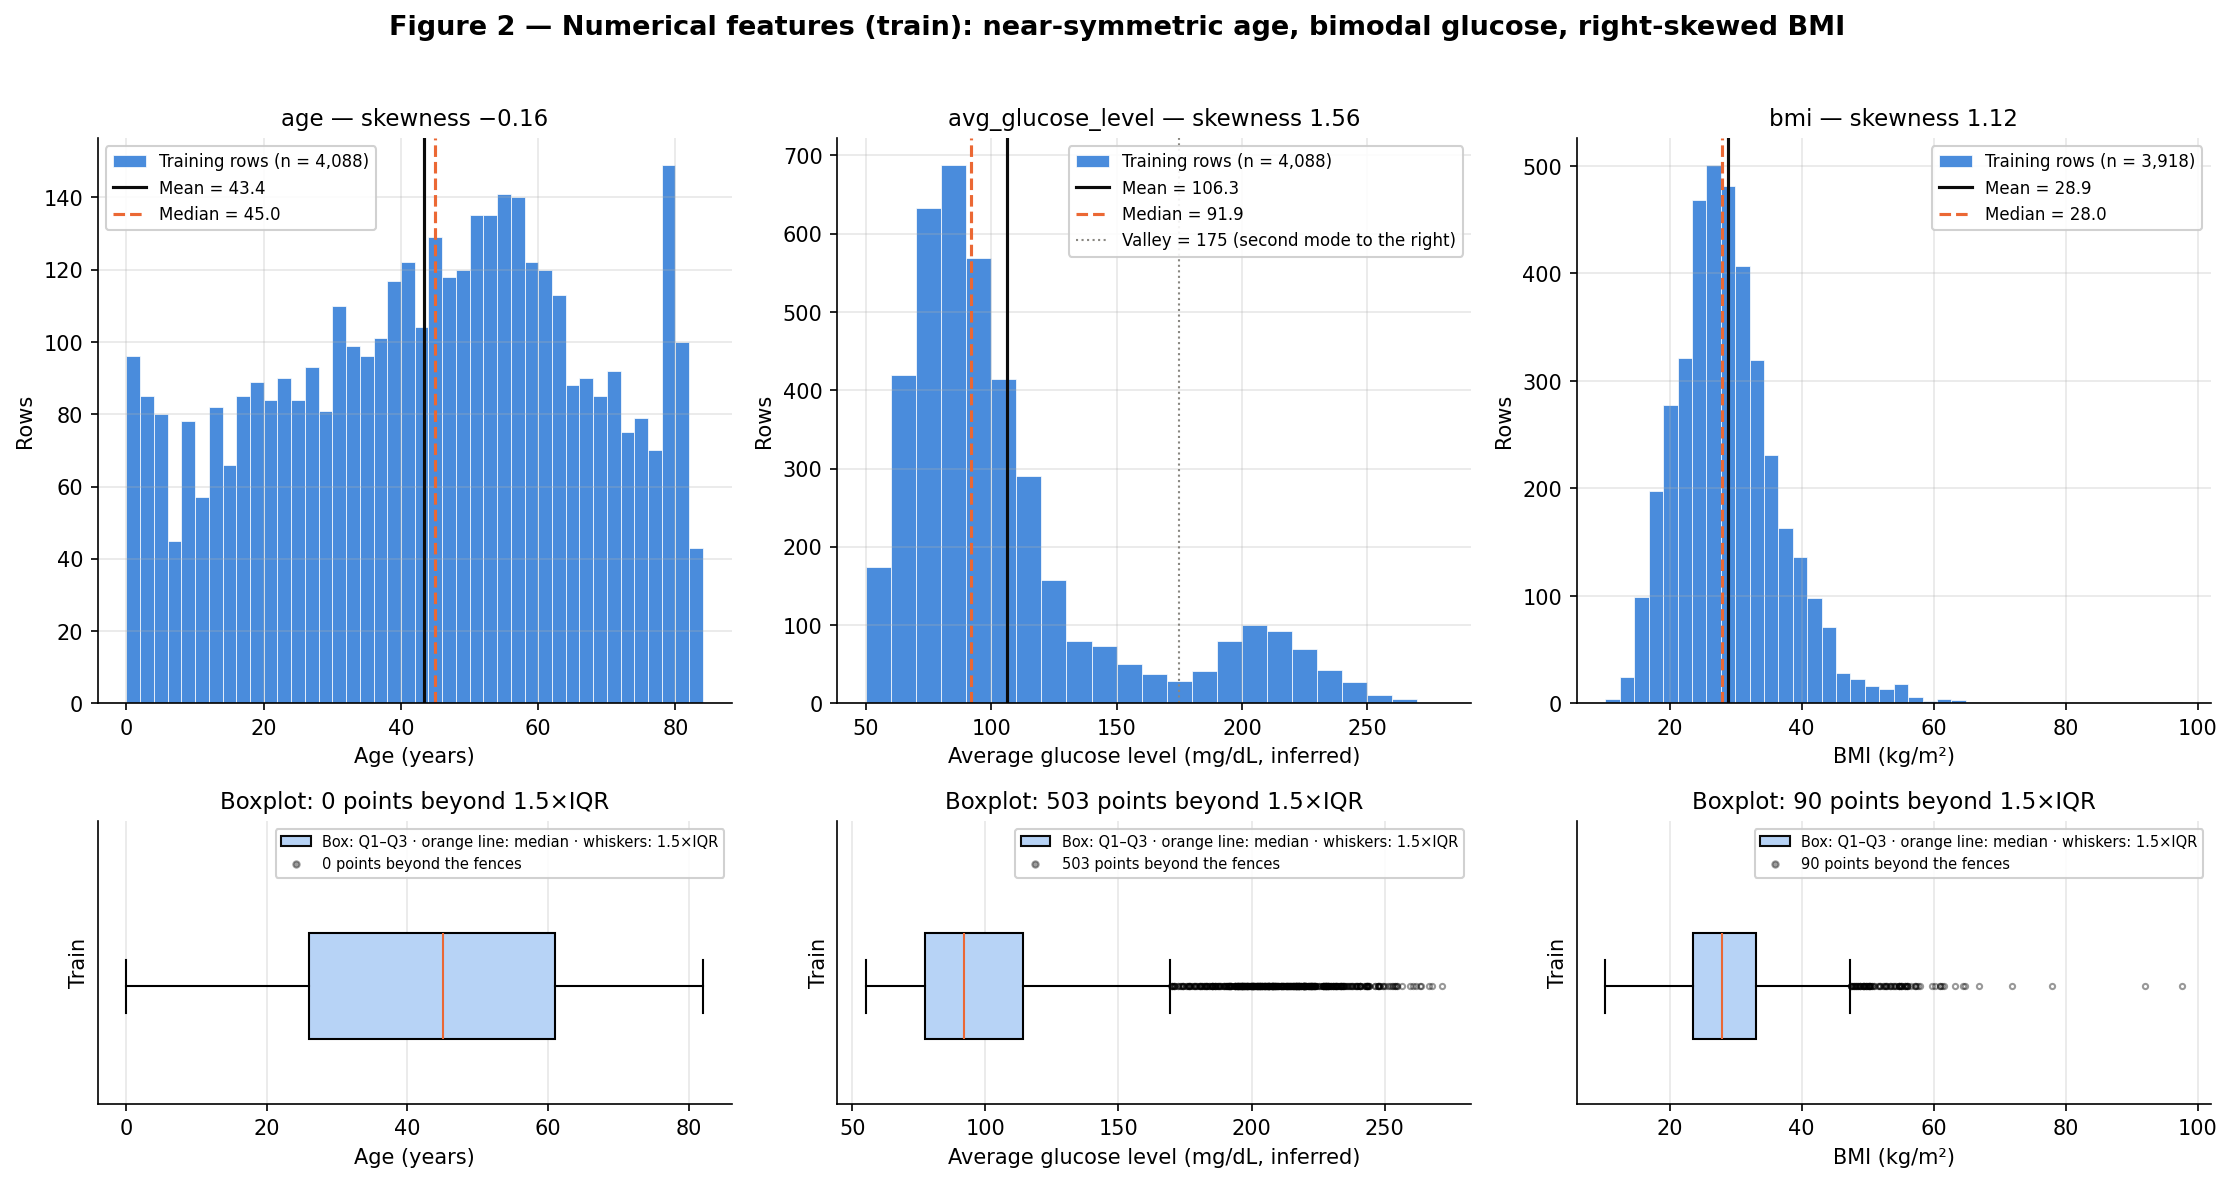

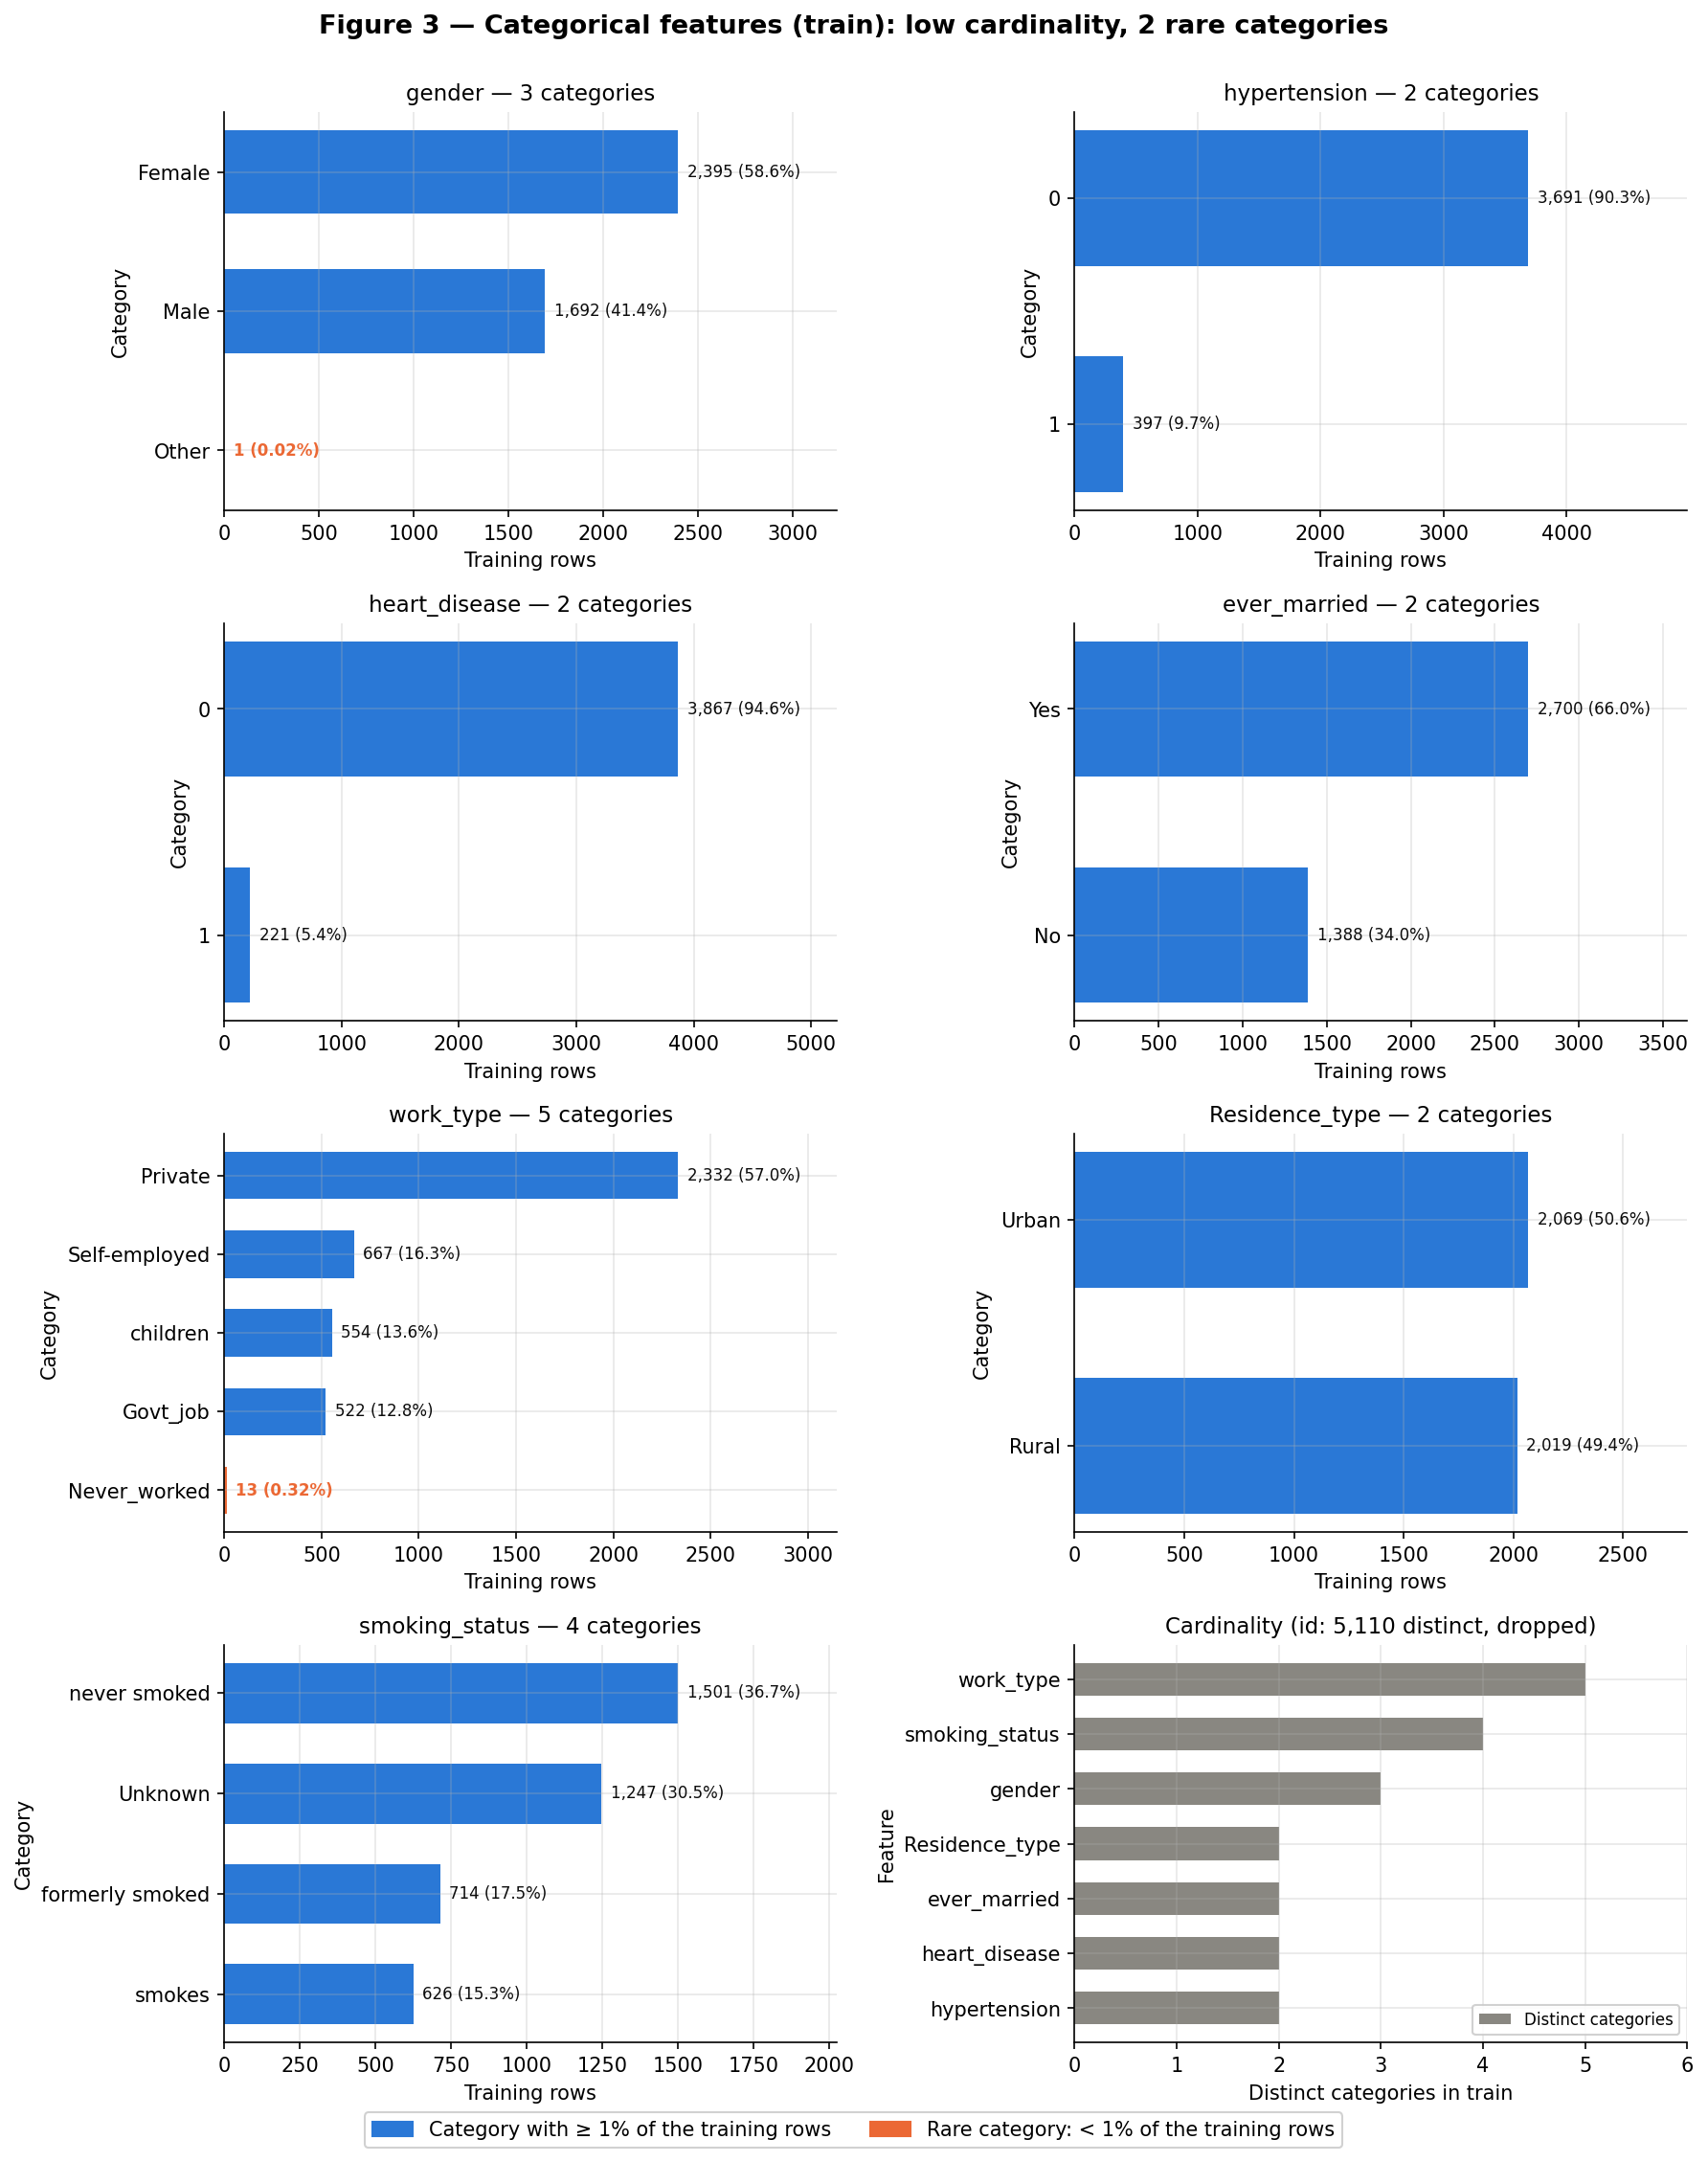

In [19]:
stage2(train, res)
show_figures(2, 3)

### Stage 3 — the features against each other and against the target (Figures 4–8)

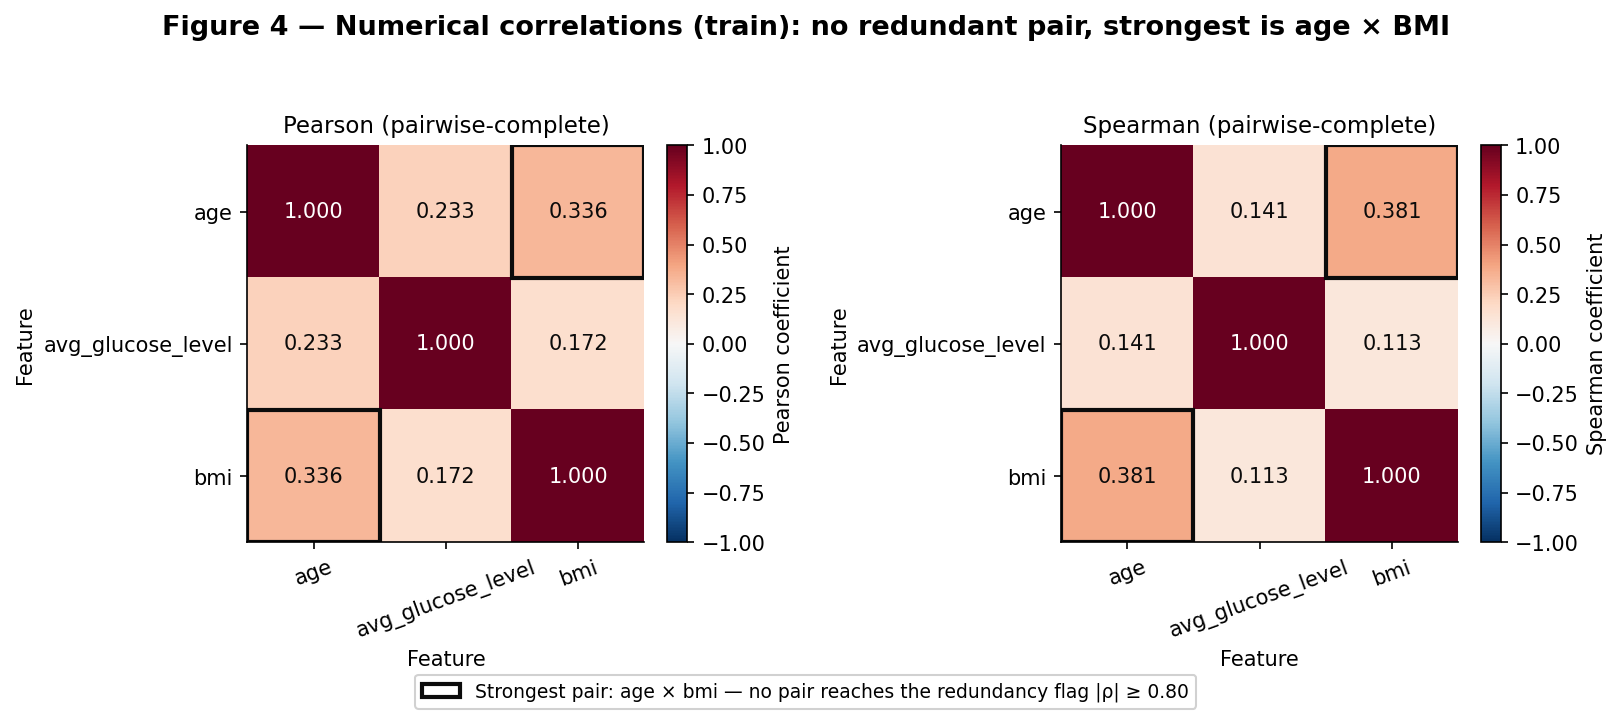

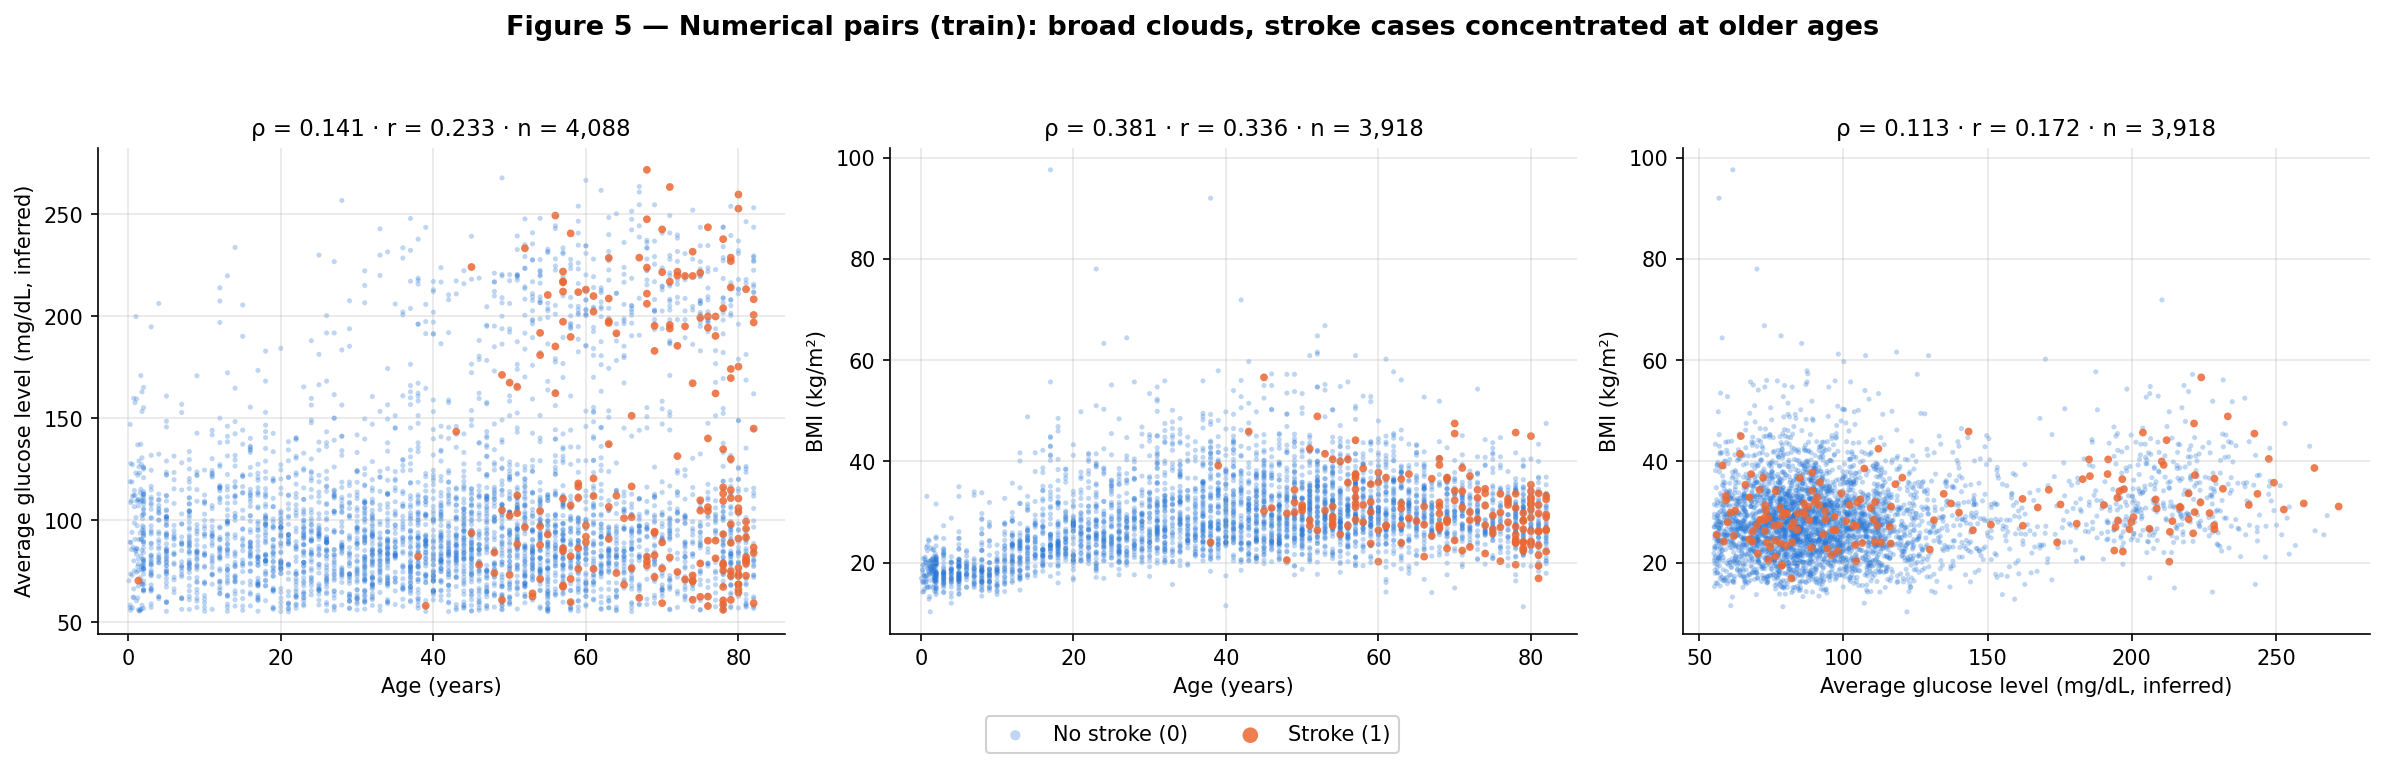

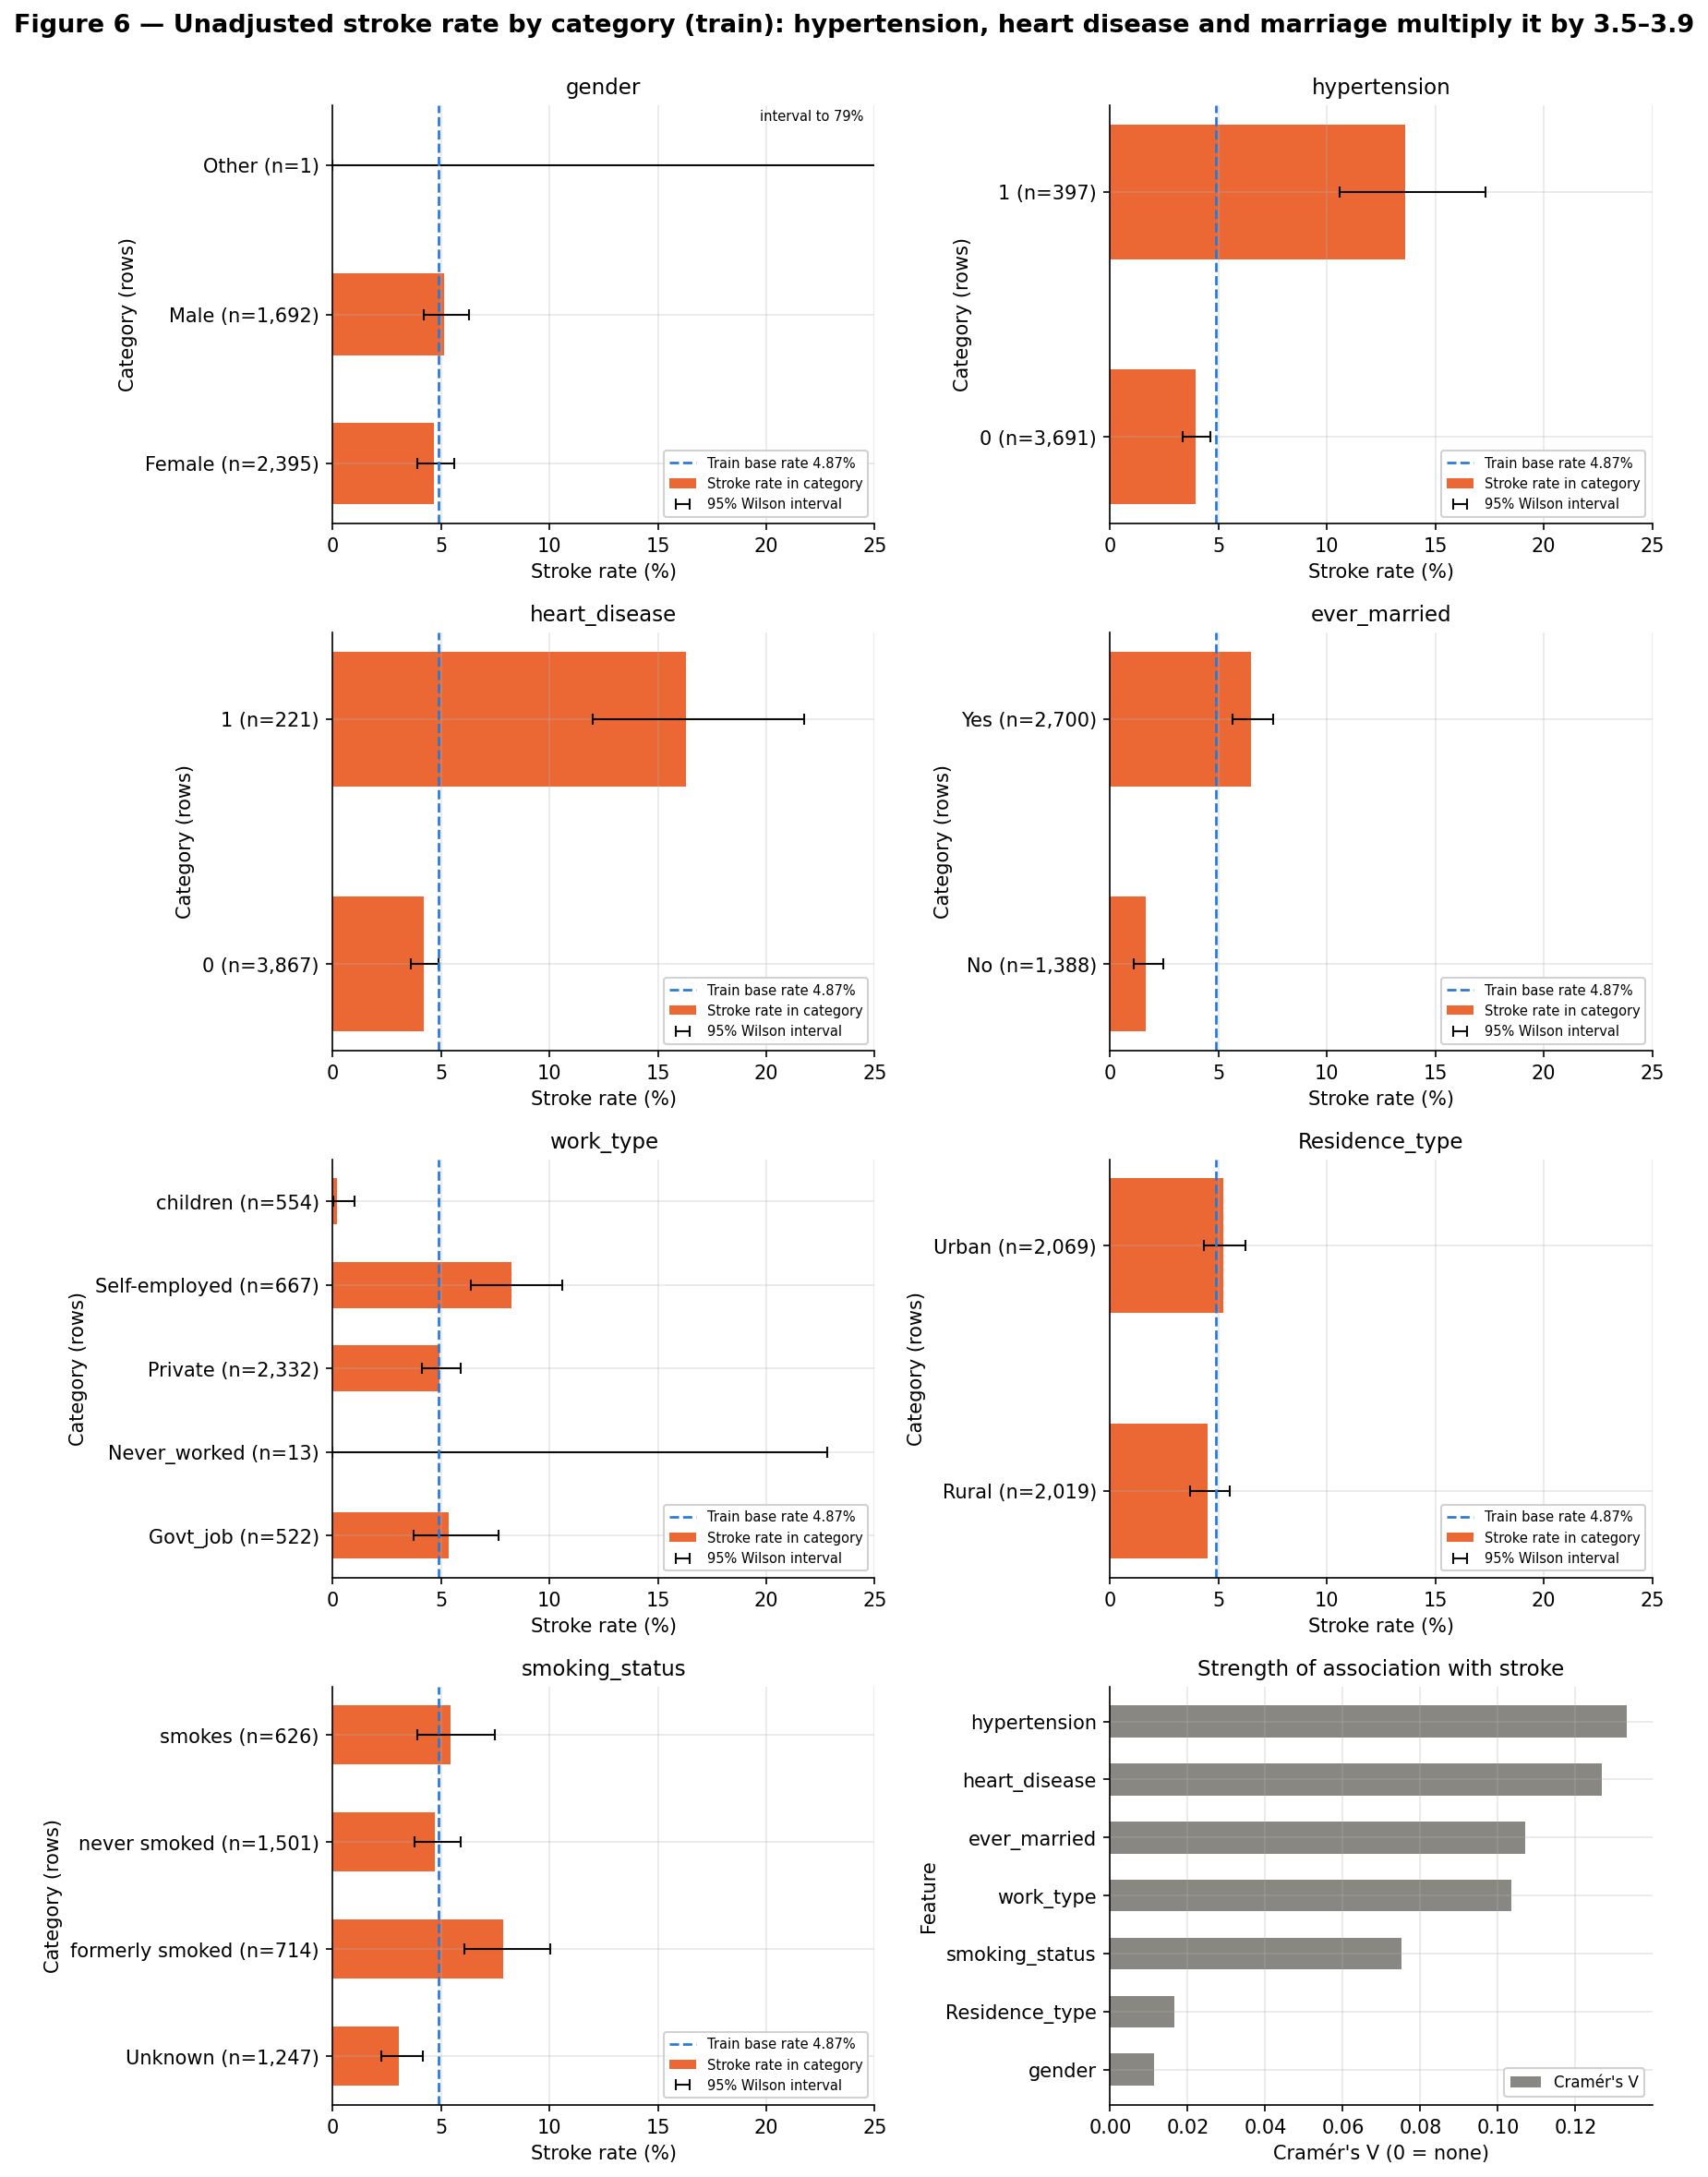

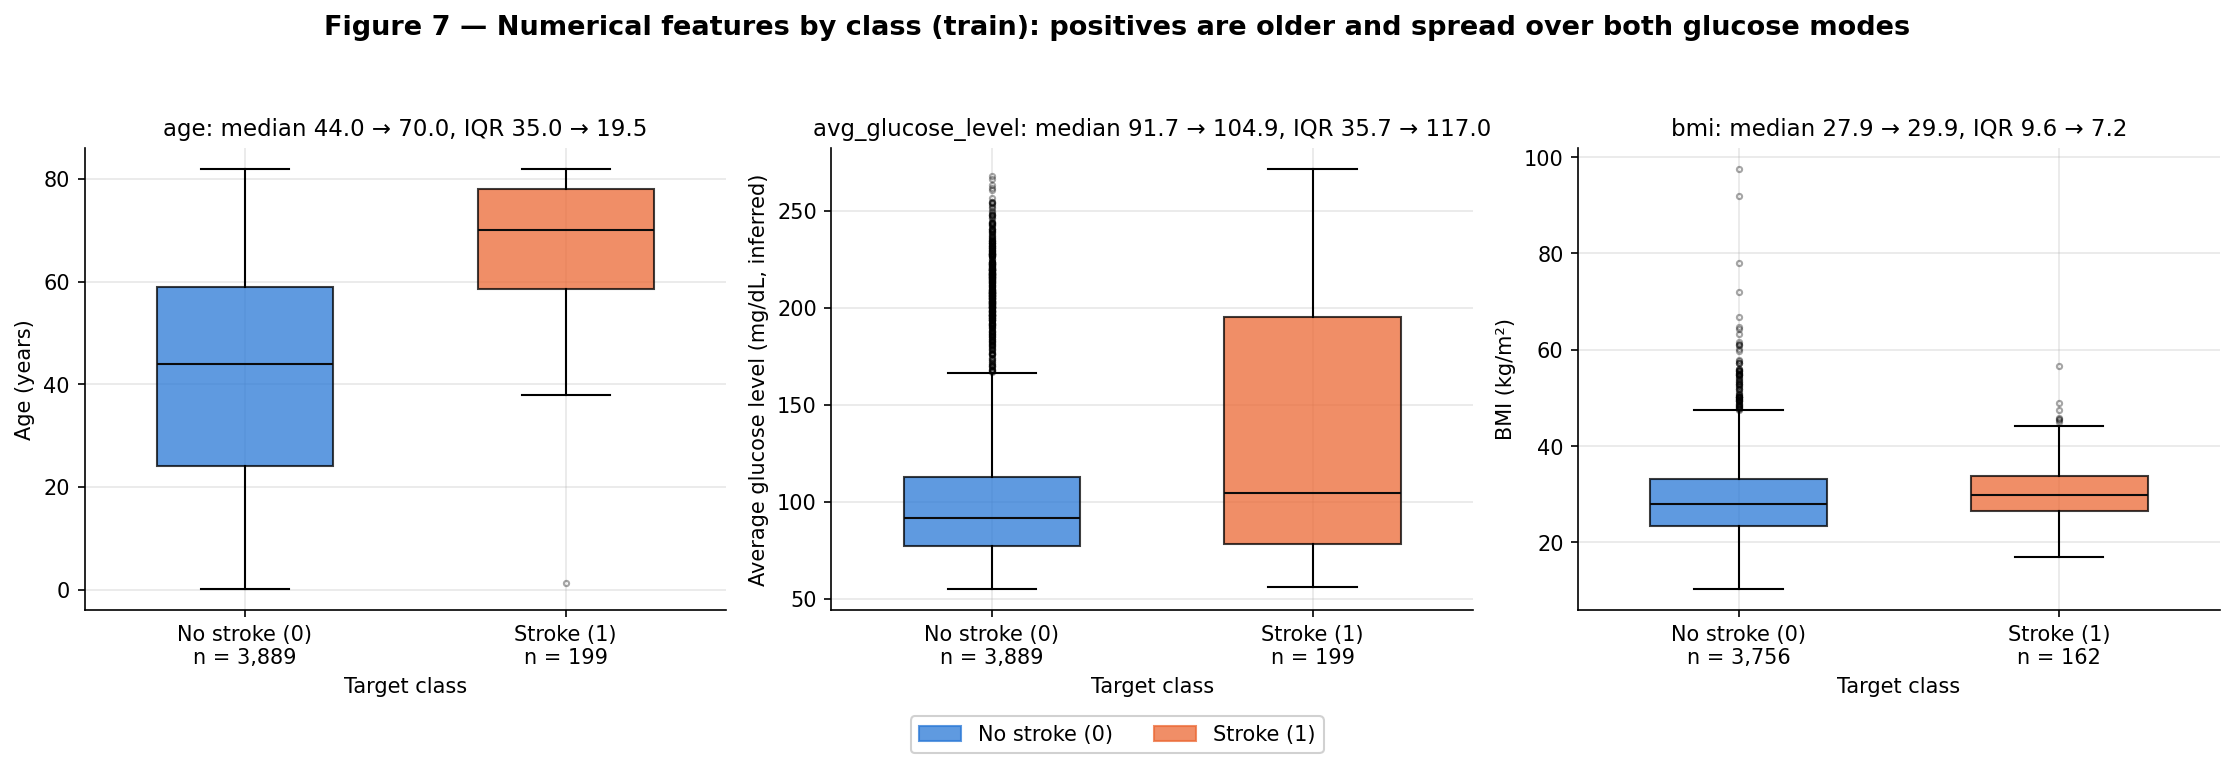

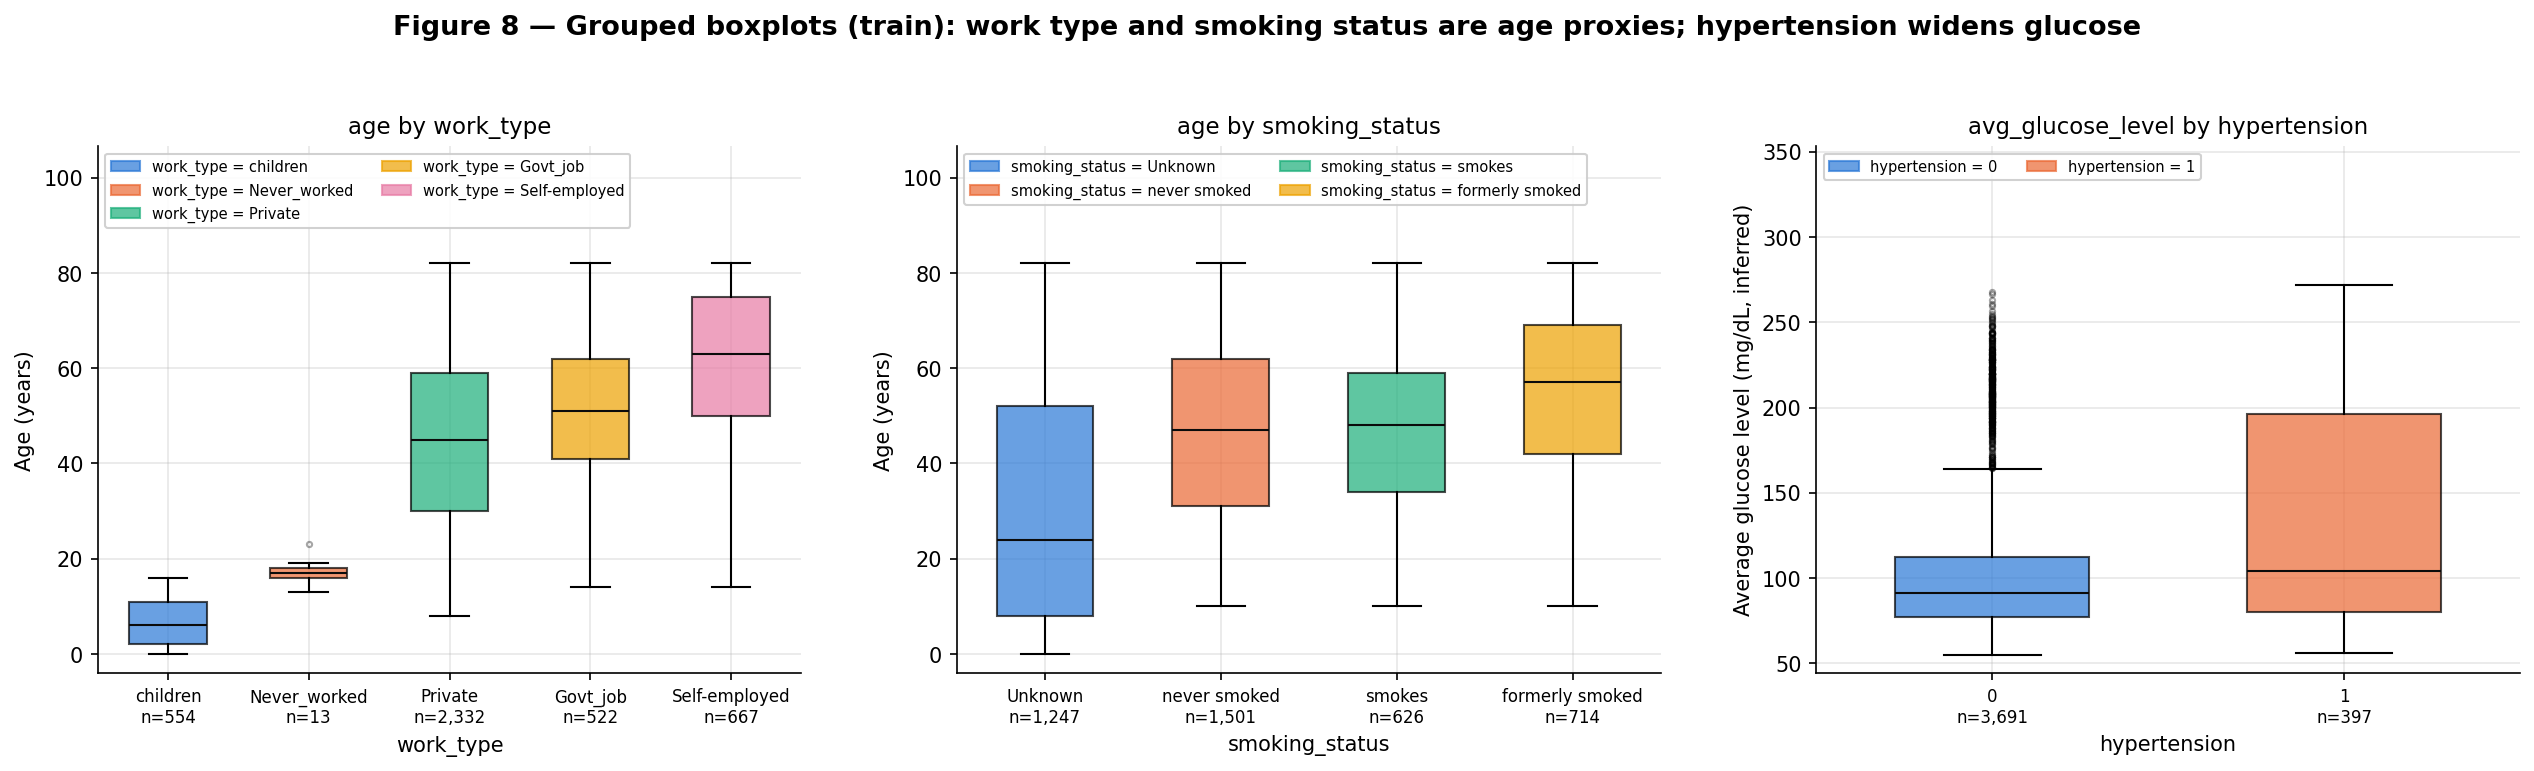

In [20]:
stage3(train, res)
show_figures(4, 5, 6, 7, 8)

In [21]:
res.write()
print(f"Stages 1-3 done: {len(res.tables)} tables, Figures 1-8 written.")

Stages 1-3 done: 11 tables, Figures 1-8 written.


### The tables of stages 1 to 3

In [22]:
show_tables("eda")

### Table 2 — Missing values per column (full file)

| column | missing (count) | missing (%) |
|---|---|---|
| id | 0 | 0.00 |
| gender | 0 | 0.00 |
| age | 0 | 0.00 |
| hypertension | 0 | 0.00 |
| heart_disease | 0 | 0.00 |
| ever_married | 0 | 0.00 |
| work_type | 0 | 0.00 |
| Residence_type | 0 | 0.00 |
| avg_glucose_level | 0 | 0.00 |
| bmi | 201 | 3.93 |
| smoking_status | 0 | 0.00 |
| stroke | 0 | 0.00 |

### Table 3 — Duplicates, impossible and inconsistent values (full file)

| check | rows |
|---|---|
| Fully duplicated rows | 0 |
| Duplicated rows ignoring id | 0 |
| Repeated id | 0 |
| Constant columns | 0 |
| Values outside the documented vocabulary | 0 |
| age <= 0 or age > 120 | 0 |
| Fractional age | 115 |
| avg_glucose_level <= 0 | 0 |
| bmi < 12 (observed) | 3 |
| bmi > 60 (observed) | 13 |
| work_type = children with age >= 18 | 0 |
| ever_married = Yes with age < 18 | 0 |
| smoking_status = smokes with age < 12 | 1 |
| smoking_status = Unknown | 1,544 |
| smoking_status = Unknown with age < 18 | 682 |

### Table 4 — Target distribution in the full file and after the stratified split

| partition | rows | stroke = 0 | stroke = 1 | stroke = 1 (%) |
|---|---|---|---|---|
| Full file | 5,110 | 4,861 | 249 | 4.87 |
| Train | 4,088 | 3,889 | 199 | 4.87 |
| Test | 1,022 | 972 | 50 | 4.89 |

### Table 5 — Descriptive statistics of the numerical features (train, observed values)

| feature | count | missing | mean | median | std | min | Q1 | Q3 | max | skewness | excess kurtosis |
|---|---|---|---|---|---|---|---|---|---|---|---|
| age | 4,088 | 0 | 43.35 | 45.00 | 22.60 | 0.08 | 26.00 | 61.00 | 82.00 | −0.16 | −0.98 |
| avg_glucose_level | 4,088 | 0 | 106.32 | 91.94 | 45.26 | 55.12 | 77.31 | 114.20 | 271.74 | 1.56 | 1.62 |
| bmi | 3,918 | 170 | 28.92 | 28.00 | 7.93 | 10.30 | 23.60 | 33.10 | 97.60 | 1.12 | 3.84 |

### Table 6 — Frequencies and cardinality of the categorical features (train)

| feature | category | count | share (%) | cardinality | rare (< 1%) |
|---|---|---|---|---|---|
| gender | Female | 2,395 | 58.59 | 3 |  |
| gender | Male | 1,692 | 41.39 | 3 |  |
| gender | Other | 1 | 0.02 | 3 | yes |
| hypertension | 0 | 3,691 | 90.29 | 2 |  |
| hypertension | 1 | 397 | 9.71 | 2 |  |
| heart_disease | 0 | 3,867 | 94.59 | 2 |  |
| heart_disease | 1 | 221 | 5.41 | 2 |  |
| ever_married | Yes | 2,700 | 66.05 | 2 |  |
| ever_married | No | 1,388 | 33.95 | 2 |  |
| work_type | Private | 2,332 | 57.05 | 5 |  |
| work_type | Self-employed | 667 | 16.32 | 5 |  |
| work_type | children | 554 | 13.55 | 5 |  |
| work_type | Govt_job | 522 | 12.77 | 5 |  |
| work_type | Never_worked | 13 | 0.32 | 5 | yes |
| Residence_type | Urban | 2,069 | 50.61 | 2 |  |
| Residence_type | Rural | 2,019 | 49.39 | 2 |  |
| smoking_status | never smoked | 1,501 | 36.72 | 4 |  |
| smoking_status | Unknown | 1,247 | 30.50 | 4 |  |
| smoking_status | formerly smoked | 714 | 17.47 | 4 |  |
| smoking_status | smokes | 626 | 15.31 | 4 |  |

### Table 7 — Pairwise correlations of the numerical features (train, observed values)

| pair | n | Pearson r | Spearman ρ |
|---|---|---|---|
| age × avg_glucose_level | 4,088 | 0.233 | 0.141 |
| age × bmi | 3,918 | 0.336 | 0.381 |
| avg_glucose_level × bmi | 3,918 | 0.172 | 0.113 |
| age × bmi, adults only (age ≥ 18) | 3,259 | 0.032 | 0.083 |

### Table 8 — Stroke rate per category (train) with 95% Wilson intervals

| feature | category | n | strokes | stroke rate (%) | 95% CI (%) |
|---|---|---|---|---|---|
| gender | Female | 2,395 | 112 | 4.68 | 3.9–5.6 |
| gender | Male | 1,692 | 87 | 5.14 | 4.2–6.3 |
| gender | Other | 1 | 0 | 0.00 | 0.0–79.3 |
| hypertension | 0 | 3,691 | 145 | 3.93 | 3.3–4.6 |
| hypertension | 1 | 397 | 54 | 13.60 | 10.6–17.3 |
| heart_disease | 0 | 3,867 | 163 | 4.22 | 3.6–4.9 |
| heart_disease | 1 | 221 | 36 | 16.29 | 12.0–21.7 |
| ever_married | No | 1,388 | 23 | 1.66 | 1.1–2.5 |
| ever_married | Yes | 2,700 | 176 | 6.52 | 5.6–7.5 |
| work_type | Govt_job | 522 | 28 | 5.36 | 3.7–7.6 |
| work_type | Never_worked | 13 | 0 | 0.00 | 0.0–22.8 |
| work_type | Private | 2,332 | 115 | 4.93 | 4.1–5.9 |
| work_type | Self-employed | 667 | 55 | 8.25 | 6.4–10.6 |
| work_type | children | 554 | 1 | 0.18 | 0.0–1.0 |
| Residence_type | Rural | 2,019 | 91 | 4.51 | 3.7–5.5 |
| Residence_type | Urban | 2,069 | 108 | 5.22 | 4.3–6.3 |
| smoking_status | Unknown | 1,247 | 38 | 3.05 | 2.2–4.2 |
| smoking_status | formerly smoked | 714 | 56 | 7.84 | 6.1–10.0 |
| smoking_status | never smoked | 1,501 | 71 | 4.73 | 3.8–5.9 |
| smoking_status | smokes | 626 | 34 | 5.43 | 3.9–7.5 |

### Table 9 — Association of each categorical feature with the target (train, χ² test of independence)

| feature | χ² | dof | p-value | Cramér's V | min expected count | p-value without the sparse categories |
|---|---|---|---|---|---|---|
| hypertension | 72.4 | 1 | 1.7e-17 | 0.133 | 19.33 | — |
| heart_disease | 65.8 | 1 | 5.0e-16 | 0.127 | 10.76 | — |
| ever_married | 46.8 | 1 | 7.9e-12 | 0.107 | 67.57 | — |
| work_type | 43.7 | 4 | 7.5e-09 | 0.103 | 0.63 | 2.6e-09 (without Never_worked) |
| smoking_status | 23.1 | 3 | 3.9e-05 | 0.075 | 30.47 | — |
| Residence_type | 1.1 | 1 | 0.29 | 0.017 | 98.28 | — |
| gender | 0.5 | 2 | 0.77 | 0.011 | 0.05 | 0.50 (without Other) |

### Table 10 — Numerical features by target class (train): location and spread

| feature | group | n | median | Q1 | Q3 | IQR | Mann–Whitney p | AUC (feature alone) |
|---|---|---|---|---|---|---|---|---|
| age | stroke = 0 | 3,889 | 44.00 | 24.00 | 59.00 | 35.00 | 3.4e-57 | 0.834 |
| age | stroke = 1 | 199 | 70.00 | 58.50 | 78.00 | 19.50 | 3.4e-57 | 0.834 |
| avg_glucose_level | stroke = 0 | 3,889 | 91.65 | 77.28 | 112.98 | 35.70 | 3.4e-06 | 0.597 |
| avg_glucose_level | stroke = 1 | 199 | 104.86 | 78.44 | 195.47 | 117.03 | 3.4e-06 | 0.597 |
| bmi | stroke = 0 | 3,756 | 27.95 | 23.50 | 33.10 | 9.60 | 2.7e-04 | 0.584 |
| bmi | stroke = 1 | 162 | 29.90 | 26.52 | 33.70 | 7.18 | 2.7e-04 | 0.584 |

### Table 11 — Numerical features grouped by categorical features (train): location and spread

| feature | group | n | median | Q1 | Q3 | IQR |
|---|---|---|---|---|---|---|
| age | work_type = Govt_job | 522 | 51.00 | 41.00 | 62.00 | 21.00 |
| age | work_type = Never_worked | 13 | 17.00 | 16.00 | 18.00 | 2.00 |
| age | work_type = Private | 2,332 | 45.00 | 30.00 | 59.00 | 29.00 |
| age | work_type = Self-employed | 667 | 63.00 | 50.00 | 75.00 | 25.00 |
| age | work_type = children | 554 | 6.00 | 2.00 | 11.00 | 9.00 |
| age | smoking_status = Unknown | 1,247 | 24.00 | 8.00 | 52.00 | 44.00 |
| age | smoking_status = formerly smoked | 714 | 57.00 | 42.00 | 69.00 | 27.00 |
| age | smoking_status = never smoked | 1,501 | 47.00 | 31.00 | 62.00 | 31.00 |
| age | smoking_status = smokes | 626 | 48.00 | 34.00 | 59.00 | 25.00 |
| avg_glucose_level | hypertension = 0 | 3,691 | 91.09 | 77.03 | 112.07 | 35.04 |
| avg_glucose_level | hypertension = 1 | 397 | 103.89 | 79.79 | 196.01 | 116.22 |

### Table 12 — Stroke rate per category within disjoint adult age bands (train)

| feature | category | rate, all ages (%) | n, 18–59 | rate, 18–59 (%) | n, ≥ 60 | rate, ≥ 60 (%) | test p, ≥ 60 |
|---|---|---|---|---|---|---|---|
| hypertension | 0 | 3.93 | 2,149 | 2.00 | 869 | 11.62 | 0.016 (Fisher) |
| hypertension | 1 | 13.60 | 161 | 7.45 | 235 | 17.87 | 0.016 (Fisher) |
| heart_disease | 0 | 4.22 | 2,263 | 2.25 | 930 | 11.94 | 0.026 (Fisher) |
| heart_disease | 1 | 16.29 | 47 | 8.51 | 174 | 18.39 | 0.026 (Fisher) |
| ever_married | No | 1.66 | 631 | 0.79 | 83 | 20.48 | 0.041 (Fisher) |
| ever_married | Yes | 6.52 | 1,679 | 2.98 | 1,021 | 12.34 | 0.041 (Fisher) |
| work_type | Govt_job | 5.36 | 362 | 2.49 | 156 | 12.18 | 0.84 (χ²) |
| work_type | Private | 4.93 | 1,663 | 2.29 | 569 | 13.53 | 0.84 (χ²) |
| work_type | Self-employed | 8.25 | 281 | 2.85 | 379 | 12.40 | 0.84 (χ²) |
| smoking_status | Unknown | 3.05 | 471 | 2.34 | 229 | 11.35 | 0.76 (χ²) |
| smoking_status | formerly smoked | 7.84 | 387 | 3.10 | 304 | 14.47 | 0.76 (χ²) |
| smoking_status | never smoked | 4.73 | 981 | 1.73 | 420 | 12.86 | 0.76 (χ²) |
| smoking_status | smokes | 5.43 | 471 | 3.18 | 151 | 12.58 | 0.76 (χ²) |


## [`code/reduction.py`](code/reduction.py) — outliers, the pipeline checks and the dimensionality reduction

In [23]:
"""Stage 4 of the EDA: preprocessing checks, outliers, PCA, t-SNE and UMAP (Figures 9-13).

The pipeline from preprocessing.py is fitted on the training rows only; the test rows are
only transformed, to report their shape and to prove that nothing was learned from them.
The projections use the transformed training matrix; the target only colors the points.
"""

import importlib.metadata
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors
from umap import UMAP


PERPLEXITIES = [5, 30, 50]
N_NEIGHBORS = [5, 15, 50]
KNN = 10   # neighborhood size of the class-enrichment and profile-agreement diagnostics

ModuleNotFoundError: No module named 'umap'

### `outliers`

In [ ]:
def outliers(X_train, y_train, res):
    """Flag with 1.5×IQR and with the modified z-score (train fences); nothing is removed."""
    m = res.metrics
    rows, flags = [], {}
    for c in NUMERICAL_FEATURES:
        x = X_train[c]   # NaN compares False, so a missing value is never flagged
        q1, q3 = x.quantile(.25), x.quantile(.75)
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        iqr_flag = (x < lo) | (x > hi)
        med = x.median()
        mad = (x - med).abs().median()
        mz_flag = 0.6745 * (x - med).abs() / mad > 3.5
        flags[c] = iqr_flag
        rows.append({"feature": c, "lower fence": lo, "upper fence": hi, "flagged (1.5×IQR)": int(iqr_flag.sum()),
                     "flagged (% of observed)": iqr_flag.sum() / x.notna().sum() * 100,
                     "stroke rate among flagged (%)":   # undefined when nothing is flagged
                     y_train[iqr_flag].mean() * 100 if iqr_flag.any() else "—",
                     "flagged (modified z > 3.5)": int(mz_flag.sum())})
    table = pd.DataFrame(rows)
    res.table(13, "Outliers in the training set (fences fitted on train; no row removed)", table,
              {"lower fence": ".2f", "upper fence": ".2f", "flagged (% of observed)": ".2f",
               "stroke rate among flagged (%)": ".2f"})
    any_flag = pd.concat(flags, axis=1).any(axis=1)
    m["outlier_rows"] = int(any_flag.sum())
    m["outlier_rows_pct"] = float(any_flag.mean() * 100)
    m["outlier_rows_positives"] = int(y_train[any_flag].sum())
    m["outlier_rows_positives_share_of_all_pos"] = float(y_train[any_flag].sum() / y_train.sum() * 100)

    # Skewness before and after log1p: the transform is a hypothesis, so it is re-measured
    rows = []
    for c in SKEWED_FEATURES:
        x = X_train[c].dropna()
        rows.append({"feature": c, "skewness (raw)": x.skew(), "skewness (log1p)": np.log1p(x).skew(),
                     "max/median (raw)": x.max() / x.median(),
                     "max/median (log1p)": np.log1p(x.max()) / np.log1p(x.median())})
    res.table(14, "Skewness of the right-skewed features before and after log1p (train, observed values)",
              pd.DataFrame(rows),
              {k: ".2f" for k in ["skewness (raw)", "skewness (log1p)", "max/median (raw)", "max/median (log1p)"]})

    # What plain standardization or min-max scaling would do with the raw tails (scaling choice, 4A). The
    # z-scores use the same median-imputed base as the pipeline, so they compare with max_abs_z_train
    imputed = X_train[SKEWED_FEATURES].fillna(X_train[SKEWED_FEATURES].median())
    m["raw_max_z"] = {c: float((imputed[c].max() - imputed[c].mean()) / imputed[c].std(ddof=0))
                      for c in SKEWED_FEATURES}
    b = X_train.bmi.dropna()
    span = b.max() - b.min()
    m["bmi_minmax_q1_median_q3"] = [float((b.quantile(q) - b.min()) / span) for q in (.25, .5, .75)]

### `pipeline_checks`

In [ ]:
def pipeline_checks(pre, X_train, X_train_t, X_test_t, names, res):
    """4C contract: no NaN, shapes, names, train-only statistics, unseen categories."""
    m = res.metrics
    m["train_shape"], m["test_shape"] = list(X_train_t.shape), list(X_test_t.shape)
    m["nan_train"], m["nan_test"] = int(np.isnan(X_train_t).sum()), int(np.isnan(X_test_t).sum())
    m["inf_train"], m["inf_test"] = int(np.isinf(X_train_t).sum()), int(np.isinf(X_test_t).sum())
    m["feature_names"] = list(names)

    # Fitted parameters equal the training statistics (not the full-file ones)
    num = pre.named_transformers_["num"]
    log = pre.named_transformers_["log"]
    rows = [{"feature": "age", "imputation median (raw scale)": num["impute"].statistics_[0],
             "scaler mean": num["scale"].mean_[0], "scaler std": num["scale"].scale_[0]}]
    for i, c in enumerate(SKEWED_FEATURES):
        rows.append({"feature": f"log1p({c})", "imputation median (raw scale)": log["impute"].statistics_[i],
                     "scaler mean": log["scale"].mean_[i], "scaler std": log["scale"].scale_[i]})
    res.table(15, "Parameters fitted by the pipeline (training rows only)", pd.DataFrame(rows),
              {"imputation median (raw scale)": ".3f", "scaler mean": ".4f", "scaler std": ".4f"})
    assert np.isclose(log["impute"].statistics_[SKEWED_FEATURES.index("bmi")], X_train.bmi.median())
    m["bmi_median_train"], m["glucose_median_train"] = (float(X_train.bmi.median()),
                                                        float(X_train.avg_glucose_level.median()))
    scaled = [i for i, n in enumerate(names) if n.startswith(("num__", "log__"))]
    m["num_means_train"] = X_train_t[:, scaled].mean(axis=0).round(6).tolist()
    m["num_stds_train"] = X_train_t[:, scaled].std(axis=0).round(6).tolist()
    m["num_means_test"] = X_test_t[:, scaled].mean(axis=0).round(4).tolist()
    m["num_stds_test"] = X_test_t[:, scaled].std(axis=0).round(4).tolist()
    m["max_abs_z_train"] = np.abs(X_train_t[:, scaled]).max(axis=0).round(2).tolist()

    # A category never seen in training, and missing values everywhere, still give a finite row of the same
    # width. The two probe rows are copies of training rows, so the test set is not touched
    probe = X_train.iloc[:2].copy()
    probe.iloc[0, probe.columns.get_loc("gender")] = "Nonbinary"
    probe.iloc[0, probe.columns.get_loc("work_type")] = "Freelancer"
    probe.iloc[1] = np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)  # sklearn warns that the unseen categories become zeros
        out = pre.transform(probe)
    gender_cols = [i for i, n in enumerate(names) if n.startswith("cat__gender_")]
    work_cols = [i for i, n in enumerate(names) if n.startswith("cat__work_type_")]
    assert out.shape == (2, len(names)) and np.isfinite(out).all()
    assert out[0, gender_cols].sum() == 0 and out[0, work_cols].sum() == 0
    bmi_col = list(names).index("log__bmi")
    low_bmi = (X_train.bmi < 12) & (X_train.age >= 18)
    m["adult_bmi_below_12_z"] = X_train_t[low_bmi.to_numpy(), bmi_col].round(2).tolist()
    indicator = list(names).index("missing__missingindicator_bmi")
    m["unseen_category_probe"] = {"gender_block": out[0, gender_cols].tolist(),
                                  "work_type_block": out[0, work_cols].tolist(),
                                  "all_missing_row_finite": bool(np.isfinite(out[1]).all()),
                                  "all_missing_row_bmi_indicator": float(out[1, indicator])}

### `neighborhood_stats`

In [ ]:
def neighborhood_stats(Z, y, profile):
    """Share of positives among the k nearest neighbors of each positive, and of identical categorical profiles."""
    nn = NearestNeighbors(n_neighbors=KNN).fit(Z)
    idx = nn.kneighbors(return_distance=False)   # no argument: each point is excluded from its own neighbors
    pos = y == 1
    enrichment = y[idx[pos]].mean() * 100
    agreement = (profile[idx] == profile[:, None]).mean() * 100
    return enrichment, agreement

### `scatter_by_class`

In [ ]:
def scatter_by_class(ax, Z, y, title, xlabel="Dimension 1 (no units)", ylabel="Dimension 2 (no units)", legend=True):
    """2D projection colored by the target, with the positives drawn larger and on top."""
    for k in (0, 1):
        sel = y == k
        ax.scatter(Z[sel, 0], Z[sel, 1], s=4 if k == 0 else 12, alpha=0.35 if k == 0 else 0.9,
                   color=CLASS_COLORS[k], label=f"{CLASS_LABELS[k]} · n = {sel.sum():,}", edgecolors="none",
                   rasterized=True)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    if legend:
        ax.legend(loc="best", markerscale=2)

### `reduction_main`

In [ ]:
def reduction_main():
    """Run stage 4 and write Tables 13-18, Figures 9-13 and results/reduction_metrics.json."""
    res = Results("reduction")
    m = res.metrics
    raw = load_raw()
    X_train, X_test, y_train, _ = split(raw)
    y = y_train.to_numpy()

    outliers(X_train, y_train, res)

    pre = build_preprocessor()
    X_train_t = pre.fit_transform(X_train)     # fit on train only
    X_test_t = pre.transform(X_test)          # test is only transformed
    names = pre.get_feature_names_out()
    pipeline_checks(pre, X_train, X_train_t, X_test_t, names, res)

    # BMI missingness vs target in train (motivates the indicator)
    miss = X_train.bmi.isna().to_numpy()
    m["train_stroke_rate_bmi_missing"] = float(y[miss].mean() * 100)
    m["train_stroke_rate_bmi_observed"] = float(y[~miss].mean() * 100)
    m["train_bmi_missing_rate_pos"] = float(miss[y == 1].mean() * 100)
    m["train_bmi_missing_rate_neg"] = float(miss[y == 0].mean() * 100)

    # Figure 9 — what motivates the missing-value and the transform choices
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    ax = axes[0]
    for i, (label, sel) in enumerate([("bmi observed", ~miss), ("bmi missing", miss)]):
        k, n = int(y[sel].sum()), int(sel.sum())
        lo, hi = wilson_interval(k, n)
        ax.bar(i, k / n * 100, color=[CLASS_COLORS[0], CLASS_COLORS[1]][i], width=0.55,
               label=f"{label}: {k:,} / {n:,} = {k / n:.2%}")
        ax.errorbar(i, k / n * 100, yerr=[[k / n * 100 - lo * 100], [hi * 100 - k / n * 100]], color="#0b0b0b",
                    capsize=4)
    ax.axhline(y.mean() * 100, color=NEUTRAL, ls="--", label=f"Train base rate {y.mean():.2%}")
    ax.set_xticks([0, 1], ["bmi observed", "bmi missing"])
    ax.set(title="Stroke rate by bmi missingness (95% Wilson)", xlabel="bmi status", ylabel="Stroke rate (%)")
    ax.legend(loc="upper left")
    for ax, c in zip(axes[1:], SKEWED_FEATURES):
        observed = X_train[c].dropna()
        j = list(names).index(f"log__{c}")
        z = X_train_t[~miss, j] if c == "bmi" else X_train_t[:, j]
        ax.hist(z, bins=40, color=CLASS_COLORS[0], alpha=0.85, edgecolor="white", linewidth=0.4,
                label=f"log1p + standardized (n = {len(z):,})")
        ax.set(title=f"{c}: skewness {observed.skew():.2f} → {np.log1p(observed).skew():.2f}",
               xlabel=f"Standardized log1p({c}) (train z-score)", ylabel="Training rows")
        ax.axvline(0, color="#0b0b0b", lw=1, label="Train mean = 0")
        ax.legend(loc="upper right")
    save_figure(fig, 9, "What the pipeline answers: informative missingness and right skew")

    # PCA on the full transformed training matrix
    pca = PCA().fit(X_train_t)
    evr = pca.explained_variance_ratio_
    cum = np.cumsum(evr)
    P = pca.transform(X_train_t)
    m["pca_evr"] = evr.round(6).tolist()
    m["pca_pc1"], m["pca_pc2"], m["pca_pc12"] = float(evr[0] * 100), float(evr[1] * 100), float(cum[1] * 100)
    for t in (0.80, 0.90, 0.95):
        m[f"pca_k_{int(t * 100)}"] = int(np.searchsorted(cum, t) + 1)
    m["pca_zero_components"] = int((pca.explained_variance_ < 1e-10).sum())
    m["total_variance"] = float(pca.explained_variance_.sum())
    n_shown = m["pca_k_95"]   # down to the component that reaches 95%
    var_table = pd.DataFrame({"component": [f"PC{i + 1}" for i in range(n_shown)],
                              "explained (%)": evr[:n_shown] * 100, "cumulative (%)": cum[:n_shown] * 100})
    res.table(16, f"PCA explained variance (first {n_shown} of {len(evr)} components)", var_table,
              {"explained (%)": ".2f", "cumulative (%)": ".2f"})
    load = pd.DataFrame({"feature": names, "PC1": pca.components_[0], "PC2": pca.components_[1]})
    # ranked by the larger |loading|, rounded so that the +/- pairs of a binary one-hot block (equal up to
    # floating-point noise) keep the order of the pipeline output on every machine
    size = load[["PC1", "PC2"]].abs().max(axis=1).round(6)
    top = load.assign(size=size).sort_values("size", ascending=False, kind="stable").drop(columns="size").head(10)
    res.table(17, "Largest PCA loadings (eigenvector coefficients) of PC1 and PC2", top,
              {"PC1": "+.3f", "PC2": "+.3f"})
    m["loadings"] = load.set_index("feature").to_dict(orient="index")
    # correlation of the PC scores with the scaled numerical columns and the indicator (helps naming the components)
    for i in (0, 1):
        m[f"pc{i + 1}_corr"] = {n: float(np.corrcoef(P[:, i], X_train_t[:, j])[0, 1])
                                for j, n in enumerate(names) if not n.startswith("cat__")}

    # Figure 10 — PCA scatter, cumulative variance, loadings
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
    scatter_by_class(axes[0], P, y, f"PC1 × PC2 ({cum[1]:.1%} of the variance)",
                     f"PC1 score ({evr[0]:.1%})", f"PC2 score ({evr[1]:.1%})")
    ax = axes[1]
    ax.bar(np.arange(1, len(evr) + 1), evr * 100, color=CLASS_COLORS[0], alpha=0.6, label="Explained by component")
    ax.plot(np.arange(1, len(evr) + 1), cum * 100, color=CLASS_COLORS[1], marker="o", ms=3, label="Cumulative")
    ax.axhline(90, color=NEUTRAL, ls="--", lw=1, label=f"90% reached at PC{m['pca_k_90']}")
    ax.set(title="Explained variance", xlabel="Principal component", ylabel="Variance explained (%)", ylim=(0, 103))
    ax.legend(loc="center right")
    ax = axes[2]
    show = top.iloc[::-1]
    bar_y = np.arange(len(show))
    ax.barh(bar_y - 0.2, show.PC1, height=0.4, color=CLASS_COLORS[0], label="PC1")
    ax.barh(bar_y + 0.2, show.PC2, height=0.4, color=CLASS_COLORS[1], label="PC2")
    ax.axvline(0, color="#0b0b0b", lw=0.8)
    ax.set_yticks(bar_y, show.feature, fontsize=8)
    ax.set(title="10 largest loadings", xlabel="Loading (eigenvector coefficient)", ylabel="Feature (pipeline output)")
    ax.legend(loc="lower right")
    save_figure(fig, 10, "PCA of the transformed training matrix: two components keep under half the variance")

    # t-SNE and UMAP, three parameter values each, on the same training matrix
    embeddings = {"PCA (2 components)": P[:, :2]}
    for perp in PERPLEXITIES:
        tsne = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto", random_state=SEED)
        embeddings[f"t-SNE perplexity {perp}"] = tsne.fit_transform(X_train_t)
        m[f"tsne_kl_{perp}"] = float(tsne.kl_divergence_)
    for nn in N_NEIGHBORS:
        um = UMAP(n_components=2, n_neighbors=nn, min_dist=0.1, random_state=SEED, n_jobs=1)
        embeddings[f"UMAP n_neighbors {nn}"] = um.fit_transform(X_train_t)

    # Null control (reduction handout): permute every raw column independently, which keeps each column's
    # distribution but destroys every association between columns and with the target (it also creates
    # combinations the data never shows, such as married children)
    rng = np.random.default_rng(SEED)
    shuffled = X_train.apply(lambda col: col.to_numpy()[rng.permutation(len(col))])
    X_shuffled_t = pre.transform(shuffled)
    y_shuffled = y[rng.permutation(len(y))]
    tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
    Z_shuffled = tsne.fit_transform(X_shuffled_t)

    # Diagnostics: neighborhood preservation, class enrichment and categorical-profile agreement
    cat_cols = [i for i, n in enumerate(names) if n.startswith("cat__") or n.startswith("missing__")]
    profile = np.array(["".join(str(int(v)) for v in row) for row in X_train_t[:, cat_cols]])
    m["n_profiles"] = int(len(set(profile)))
    rows = []
    enr, agr = neighborhood_stats(X_train_t, y, profile)
    rows.append({"space": "Original 24 dimensions", "trustworthiness k=5": "—", "trustworthiness k=30": "—",
                 "positives among 10-NN of positives (%)": enr, "same categorical profile among 10-NN (%)": agr})
    for name, Z in embeddings.items():
        enr, agr = neighborhood_stats(Z, y, profile)
        rows.append({"space": name, "trustworthiness k=5": trustworthiness(X_train_t, Z, n_neighbors=5),
                     "trustworthiness k=30": trustworthiness(X_train_t, Z, n_neighbors=30),
                     "positives among 10-NN of positives (%)": enr, "same categorical profile among 10-NN (%)": agr})
    profile_shuffled = np.array(["".join(str(int(v)) for v in row) for row in X_shuffled_t[:, cat_cols]])
    enr, agr = neighborhood_stats(Z_shuffled, y_shuffled, profile_shuffled)
    rows.append({"space": "Control: t-SNE perplexity 30 on independently shuffled columns",
                 "trustworthiness k=5": trustworthiness(X_shuffled_t, Z_shuffled, n_neighbors=5),
                 "trustworthiness k=30": trustworthiness(X_shuffled_t, Z_shuffled, n_neighbors=30),
                 "positives among 10-NN of positives (%)": enr, "same categorical profile among 10-NN (%)": agr})
    m["n_profiles_shuffled"] = int(len(set(profile_shuffled)))
    diag = pd.DataFrame(rows)
    res.table(18, f"Projection diagnostics (train, {len(y):,} rows; base rate {y.mean():.2%})", diag,
              {"trustworthiness k=5": ".3f", "trustworthiness k=30": ".3f",
               "positives among 10-NN of positives (%)": ".2f", "same categorical profile among 10-NN (%)": ".1f"})
    m["projection_diagnostics"] = diag.to_dict(orient="records")

    for number, method, params, key in [(11, "t-SNE", PERPLEXITIES, "perplexity"),
                                        (12, "UMAP", N_NEIGHBORS, "n_neighbors")]:
        fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
        for ax, p in zip(axes, params):
            scatter_by_class(ax, embeddings[f"{method} {key} {p}"], y, f"{key} = {p}", legend=False)
        fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, markerscale=2,
                   bbox_to_anchor=(0.5, -0.05), fontsize=10)
        save_figure(fig, number, f"{method} of the transformed training matrix: three {key} values, "
                                 "colored by the target")

    # Figure 13 — what the nonlinear maps group by: color by a categorical feature and by age
    fig, axes = plt.subplots(3, 2, figsize=(12, 16))   # one row per method: work_type on the left, age on the right
    shown = ["PCA (2 components)", "t-SNE perplexity 30", "UMAP n_neighbors 15"]
    work = X_train.work_type.to_numpy()
    order = X_train.work_type.value_counts().index.tolist()   # most frequent first; every category is drawn
    axis_names = {"PCA (2 components)": ("PC1 score", "PC2 score")}
    for ax, name in zip(axes[:, 0], shown):
        Z = embeddings[name]
        for k, color in zip(order, GROUP_COLORS):
            sel = work == k
            ax.scatter(Z[sel, 0], Z[sel, 1], s=4, alpha=0.6, color=color, label=f"{k} (n={sel.sum():,})",
                       edgecolors="none", rasterized=True)
        xl, yl = axis_names.get(name, ("Dimension 1 (no units)", "Dimension 2 (no units)"))
        ax.set(title=f"{name} — colored by work_type", xlabel=xl, ylabel=yl)
        ax.legend(loc="best", markerscale=3, fontsize=7)
    for ax, name in zip(axes[:, 1], shown):
        Z = embeddings[name]
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=X_train.age, cmap="Blues", s=4, edgecolors="none", rasterized=True)
        positive = y == 1
        ax.scatter(Z[positive, 0], Z[positive, 1], s=14, facecolors="none", edgecolors=CLASS_COLORS[1], lw=0.8,
                   label=f"{CLASS_LABELS[1]} · n = {positive.sum()}")
        fig.colorbar(sc, ax=ax, fraction=0.046, label=UNITS["age"])
        xl, yl = axis_names.get(name, ("Dimension 1 (no units)", "Dimension 2 (no units)"))
        ax.set(title=f"{name} — colored by age", xlabel=xl, ylabel=yl)
        ax.legend(loc="best", fontsize=7)
    save_figure(fig, 13, "What the maps group by: categorical profiles make the islands, age orders the positives")

    m["versions"] = {p: importlib.metadata.version(p) for p in
                     ["numpy", "pandas", "scipy", "scikit-learn", "umap-learn", "matplotlib"]}
    m["python"] = platform.python_version()
    res.write()
    print(f"Stage 4 done: train {X_train_t.shape}, test {X_test_t.shape}, Figures 9-13 written.")

# Run — outliers, pipeline and reduction

`reduction.main()`: Tables 13–20 and Figures 9–13.

In [ ]:
reduction_main()
show_figures(9, 10, 11, 12, 13)

### The tables of this stage

In [ ]:
show_tables("reduction")